# ***Import and Load***

In [ ]:
# ============================================
# Cell 1: Imports & Settings
# ============================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from IPython.display import display, Markdown
import warnings
warnings.simplefilter("ignore")

# General display options
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Modern, vivid plotting style
plt.style.use("seaborn-v0_8-darkgrid")
sns.set_theme(style="whitegrid", context="talk", palette="viridis")

# Helper to annotate bar plots
def annotate_bars(ax, fmt="{:.0f}"):
    for p in ax.patches:
        height = p.get_height()
        if np.isnan(height):
            continue
        ax.annotate(
            fmt.format(height),
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=9,
            xytext=(0, 3),
            textcoords="offset points",
            rotation=0,
        )

In [ ]:
# ============================================
# Cell 2: Load Datasets
# ============================================

electronics = pd.read_csv("../Dataset/shopee_electronics_data.csv")
fashion = pd.read_csv("../Dataset/shopee_fashion_data.csv")


# **Task 1: Overview**

In [ ]:
# ============================================
# Task 1 – Data Overview
# ============================================

def dataset_overview(df, name):
    print(f"===== {name} =====")
    # Structure summary
    print("Shape (rows, columns):", df.shape)
    print("\nData types:")
    print(df.dtypes)
    print("\nInfo():")
    df.info()
    print("\nFirst 5 rows:")
    display(df.head())
    print("\nLast 5 rows:")
    display(df.tail())
    print("\nRandom 5 rows:")
    display(df.sample(5, random_state=42))
    print("\n" + "="*60 + "\n")

dataset_overview(electronics, "Electronics – Raw")
dataset_overview(fashion, "Fashion – Raw")

===== Electronics – Raw =====
Shape (rows, columns): (2244, 20)

Data types:
transaction_id          object
seller_id               object
product_id              object
product_name            object
category                object
brand                   object
region                  object
order_date              object
quantity                 int64
unit_price             float64
total_price            float64
discount_pct           float64
shipping_fee           float64
payment_method          object
order_status            object
customer_rating        float64
review_count           float64
is_flash_sale             bool
shopee_coins_earned      int64
seller_rating          float64
dtype: object

Info():
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2244 entries, 0 to 2243
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       2244 non-null   object 
 1   seller_id         

,transaction_id,seller_id,product_id,product_name,category,brand,region,order_date,quantity,unit_price,total_price,discount_pct,shipping_fee,payment_method,order_status,customer_rating,review_count,is_flash_sale,shopee_coins_earned,seller_rating
0,TXN-E10001,SHP-S9279,PROD-CAM674,Sony ZV-E10,Cameras,Samsung,Indonesia,2020-02-12,3,876.52,"1,867.37",29.50,13.53,Shopee Coins,Completed,2.70,244.00,True,64,4.40
1,TXN-E10002,SHP-S2584,PROD-CAM452,DJI Osmo Pocket 3,Cameras,Oppo,Malaysia,2022-05-21,1,"1,616.92","1,128.57",30.40,3.19,Bank Transfer,Completed,1.60,"2,757.00",True,53,4.00
2,TXN-E10003,SHP-S1750,PROD-GAM891,Razer DeathAdder V3,Gaming Accessories,Razer,Singapore,2020-08-15,7,53.09,365.60,3.20,5.86,Shopee Coins,Returned,2.40,"1,575.00",False,0,4.50
3,TXN-E10004,SHP-S3803,PROD-GAM350,Logitech G Pro X Keyboard,Gaming Accessories,HP,Malaysia,2019-12-01,6,87.54,-498.21,6.50,7.11,Cash on Delivery,Cancelled,3.70,584.00,False,0,4.30
4,TXN-E10005,SHP-S4456,PROD-HEA680,Samsung Galaxy Buds 2,Headphones,Dell,Singapore,2023-11-30,6,263.92,"1,065.39",33.70,15.52,Credit Card,Returned,4.20,"3,286.00",False,0,4.90



Last 5 rows:


,transaction_id,seller_id,product_id,product_name,category,brand,region,order_date,quantity,unit_price,total_price,discount_pct,shipping_fee,payment_method,order_status,customer_rating,review_count,is_flash_sale,shopee_coins_earned,seller_rating
2239,TXN-E12041,SHP-S7319,PROD-LAP834,Lenovo IdeaPad 5,Laptops,Razer,Singapore,2023-06-30,4,"1,771.50","4,273.29",39.80,7.52,Bank Transfer,Completed,3.40,"2,111.00",False,27,4.00
2240,TXN-E12153,SHP-S9801,PROD-CAM356,Canon EOS R50,Cameras,Huawei,Malaysia,2019-05-20,7,"1,204.45","5,353.99",36.60,8.64,Credit Card,Completed,1.80,"4,445.00",False,368,4.20
2241,TXN-E12032,SHP-S8449,PROD-LAP215,Acer Aspire 5,Laptops,Realme,Malaysia,2019-01-16,7,"1,412.09","8,078.52",18.30,2.78,ShopeePay,Completed,2.60,"3,875.00",False,152,4.60
2242,TXN-E10774,SHP-S1801,PROD-TAB510,iPad 10th Gen,Tablets,Apple,Singapore,2020-08-30,10,834.91,"7,607.94",9.10,18.61,Credit Card,Completed,4.80,"3,473.00",False,290,4.90
2243,TXN-E11839,SHP-S5640,PROD-SMA790,Xiaomi Smart Band 7,Smart Watches,Acer,Indonesia,2020-12-29,2,338.75,614.74,11.00,11.76,ShopeePay,Completed,1.80,"2,764.00",False,15,4.60



Random 5 rows:


,transaction_id,seller_id,product_id,product_name,category,brand,region,order_date,quantity,unit_price,total_price,discount_pct,shipping_fee,payment_method,order_status,customer_rating,review_count,is_flash_sale,shopee_coins_earned,seller_rating
1666,TXN-E11667,SHP-S8289,PROD-GAM488,Logitech G Pro X Keyboard,Gaming Accessories,Huawei,Malaysia,2023-05-17,5,47.57,182.42,24.80,3.56,Credit Card,Completed,3.60,"4,672.00",False,19,4.20
2239,TXN-E12041,SHP-S7319,PROD-LAP834,Lenovo IdeaPad 5,Laptops,Razer,Singapore,2023-06-30,4,"1,771.50","4,273.29",39.80,7.52,Bank Transfer,Completed,3.40,"2,111.00",False,27,4.00
1550,TXN-E11551,SHP-S3456,PROD-HEA113,JBL Tune 760NC,Headphones,HP,Indonesia,2019-05-11,8,176.82,865.51,39.70,12.53,ShopeePay,Cancelled,NaN,147.00,True,0,4.00
240,TXN-E10241,SHP-S6437,PROD-MOB400,Huawei nova 11,Mobile Phones,Razer,Malaysia,2020-03-23,3,668.94,"1,605.13",20.80,15.73,Credit Card,Completed,3.10,753.00,False,59,4.00
686,TXN-E10687,SHP-S2633,PROD-SMA771,Apple Watch SE 2,Smart Watches,Apple,Indonesia,2022-03-26,4,488.01,"1,319.20",33.30,17.19,Cash on Delivery,Completed,4.00,"2,475.00",False,56,3.90


... (2 outputs left out)


Last 5 rows:


,transaction_id,seller_id,product_id,product_name,category,brand,region,order_date,size,color,quantity,unit_price,total_price,discount_pct,shipping_fee,payment_method,order_status,customer_rating,review_count,is_flash_sale,shopee_coins_earned,seller_rating
2239,TXN-F20424,SHP-S2769,PROD-KID120,Toddler Romper,Kids' Fashion,Pull&Bear,Philippines,2020-01-31,L,Red,7,28.94,164.69,18.90,0.40,ShopeePay,Completed,4.00,"8,479.00",False,5,NaN
2240,TXN-F21683,SHP-S2002,PROD-SHO178,Nike Air Force 1,Shoes,Nike,thailand,2022-07-13,S,Navy,11,40.39,422.22,5.30,1.48,Credit Card,Returned,2.90,"8,600.00",False,0,4.90
2241,TXN-F21339,SHP-S5530,PROD-KID743,Kids Graphic Tee,Kids' Fashion,Converse,Vietnam,2023-04-05,XL,Brown,6,27.37,110.87,33.30,1.34,ShopeePay,Returned,4.50,"9,551.00",True,0,4.90
2242,TXN-F22051,SHP-S3367,PROD-KID463,Kids Graphic Tee,Kids' Fashion,Local Brand,VN,2020-12-09,XXL,Green,8,46.23,200.28,47.10,4.63,ShopeePay,Completed,4.70,"9,656.00",False,9,3.40
2243,TXN-F20155,SHP-S9209,PROD-TRA507,Ao Dai Set,Traditional Wear,Adidas,Thailand,2021-04-12,XL,Beige,7,142.17,943.95,5.50,3.50,Shopee Coins,Completed,NaN,NaN,True,2,4.90



Random 5 rows:


,transaction_id,seller_id,product_id,product_name,category,brand,region,order_date,size,color,quantity,unit_price,total_price,discount_pct,shipping_fee,payment_method,order_status,customer_rating,review_count,is_flash_sale,shopee_coins_earned,seller_rating
1666,TXN-F21667,SHP-S8812,PROD-KID970,Girls Party Dress,Kids' Fashion,Nike,Vietnam,2019-11-20,XXL,Brown,5,23.45,91.58,24.30,2.82,Credit Card,Completed,1.50,"3,300.00",False,1,3.10
2239,TXN-F20424,SHP-S2769,PROD-KID120,Toddler Romper,Kids' Fashion,Pull&Bear,Philippines,2020-01-31,L,Red,7,28.94,164.69,18.90,0.40,ShopeePay,Completed,4.00,"8,479.00",False,5,NaN
1550,TXN-F21551,SHP-S3882,PROD-MEN255,Casual Chinos,Men's Clothing,Pull&Bear,Vietnam,2019-06-06,Free Size,White,8,84.44,438.64,35.80,4.96,Shopee Coins,Completed,4.80,"3,461.00",False,24,4.50
240,TXN-F20241,SHP-S8613,PROD-TRA996,Barong Tagalog,Traditional Wear,Pull&Bear,Vietnam,2020-09-19,M,Beige,14,196.77,"2,200.19",20.20,1.88,Bank Transfer,Cancelled,3.20,"10,423.00",True,0,3.90
686,TXN-F20687,SHP-S7766,PROD-KID921,Boys Jogger Set,Kids' Fashion,Bershka,Thailand,2019-05-06,XL,Yellow,1,25.31,24.48,21.20,4.54,Shopee Coins,Completed,4.10,NaN,False,3,3.50


# ***Columnwise Data Error Summary (Part of task: 2)***

In [ ]:
def issues_table(df, name):
    print(f"===== {name}: Data Issues Summary =====")

    n_rows = len(df)

    # 1) Missing values per column
    missing_count = df.isna().sum()

    # 2) Invalid data count
    invalid_data_count = pd.Series(0, index=df.columns, dtype="float")

    # 2a) customer_rating & seller_rating: valid range [1, 5]
    for rating_col in ["customer_rating", "seller_rating"]:
        if rating_col in df.columns:
            bad_mask = (df[rating_col] < 1) | (df[rating_col] > 5)
            invalid_data_count.loc[rating_col] = bad_mask.sum()

    # 2b) discount_pct: valid range [0, 100]
    if "discount_pct" in df.columns:
        bad_disc_mask = (df["discount_pct"] < 0) | (df["discount_pct"] > 100)
        invalid_data_count.loc["discount_pct"] = bad_disc_mask.sum()

    # 3) Negative values count (total_price & quantity)
    negative_value_count = pd.Series(0, index=df.columns, dtype="float")

    if "total_price" in df.columns:
        negative_value_count.loc["total_price"] = (df["total_price"] < 0).sum()

    if "quantity" in df.columns:
        negative_value_count.loc["quantity"] = (df["quantity"] < 0).sum()

    # 4) Combine into a single DataFrame
    issues_df = pd.DataFrame({
        "missing_count":        missing_count,
        "invalid_data_count":   invalid_data_count,
        "negative_value_count": negative_value_count
    })

    # 5) Overall issue score
    issues_df["total_issue_score"] = (
        issues_df["missing_count"]
        + issues_df["invalid_data_count"]
        + issues_df["negative_value_count"]
    )

    for col in ["missing_count", "invalid_data_count",
                "negative_value_count", "total_issue_score"]:
        issues_df[col] = issues_df[col].astype(int)

    issues_df = issues_df.sort_values("total_issue_score", ascending=False)

    # 6) Colour coding
    def highlight_row(row):
        max_score = issues_df["total_issue_score"].max()
        if row["total_issue_score"] == max_score and max_score > 0:
            return ["background-color: salmon"] * len(row)
        return [""] * len(row)

    styled = (issues_df.style
              .apply(highlight_row, axis=1)
              .background_gradient(subset=[
                  "missing_count", "invalid_data_count",
                  "negative_value_count", "total_issue_score"
              ], cmap="YlOrRd"))

    display(styled)
    return issues_df


# Example usage:
issues_electronics = issues_table(electronics, "Electronics")
issues_fashion     = issues_table(fashion,     "Fashion")

===== Electronics: Data Issues Summary =====


,missing_count,invalid_data_count,negative_value_count,total_issue_score
customer_rating,152,22,0,174
review_count,111,0,0,111
seller_rating,89,0,0,89
quantity,0,0,45,45
total_price,0,0,44,44
discount_pct,0,22,0,22
seller_id,0,0,0,0
transaction_id,0,0,0,0
product_name,0,0,0,0
product_id,0,0,0,0


===== Fashion: Data Issues Summary =====


,missing_count,invalid_data_count,negative_value_count,total_issue_score
customer_rating,160,22,0,182
review_count,114,0,0,114
seller_rating,91,0,0,91
quantity,0,0,45,45
total_price,0,0,44,44
discount_pct,0,22,0,22
brand,0,0,0,0
category,0,0,0,0
product_name,0,0,0,0
product_id,0,0,0,0


# ***Basic Cleaning***

In [ ]:
# ============================================
# Cell 1: Clean pricing

  # 1) quantity -> Absolute Value
  # 2) total_price -> Absolute Value
  # 3) recompute discount_pct ONLY for <0 or >100
  # 4) cross-check consistency
# ============================================

def recompute_discount_pct(df, name="", tol=1e-2):
    print(f"========== {name}: recompute discount_pct from formula ==========")
    df = df.copy()

    # --- Step 1: quantity positive ---
    neg_q = (df["quantity"] < 0).sum()
    print("Negative quantity rows before:", neg_q)
    df.loc[df["quantity"] < 0, "quantity"] = df.loc[df["quantity"] < 0, "quantity"].abs()
    print("Negative quantity rows after :", (df["quantity"] < 0).sum())
    print()

    # --- Step 2: total_price positive ---
    neg_tp = (df["total_price"] < 0).sum()
    print("Negative total_price rows before:", neg_tp)
    df.loc[df["total_price"] < 0, "total_price"] = df.loc[df["total_price"] < 0, "total_price"].abs()
    print("Negative total_price rows after :", (df["total_price"] < 0).sum())
    print()

    # Prepare numeric arrays
    q  = df["quantity"].astype(float)
    u  = df["unit_price"].astype(float)
    tp = df["total_price"].astype(float)
    s  = df["shipping_fee"].astype(float)
    d0 = df["discount_pct"].astype(float)   # original discount_pct

    # --- Step 3: recompute discount_pct ONLY where d0 < 0 or d0 > 100 ---
    base = q * u
    base_nonzero = base > 0

    # rows where original discount_pct is clearly invalid
    disc_bad = (d0 < 0) | (d0 > 100)
    print("Rows with discount_pct < 0 or > 100 (candidates to fix):", disc_bad.sum())

    # ratio = (tp - s) / (q * u)
    ratio = pd.Series(np.nan, index=df.index, dtype="float")
    ratio.loc[base_nonzero] = (tp[base_nonzero] - s[base_nonzero]) / base[base_nonzero]

    # Only keep rows where 0 <= ratio <= 1
    valid_ratio = ratio.between(0, 1)

    d_new = 100.0 * (1.0 - ratio)
    # Final mask: bad original discount, base>0, ratio in [0,1]
    impute_mask = disc_bad & base_nonzero & valid_ratio

    print("Rows where discount_pct will be recomputed from formula:", impute_mask.sum())
    print("Rows with invalid discount_pct that cannot be reliably fixed:",
          disc_bad.sum() - impute_mask.sum())

    # Apply new discount_pct only on those rows
    df.loc[impute_mask, "discount_pct"] = d_new[impute_mask]

    # Optional: round
    df["discount_pct"] = df["discount_pct"].round(4)
    df["unit_price"]   = df["unit_price"].round(2)
    df["shipping_fee"] = df["shipping_fee"].round(2)
    df["total_price"]  = df["total_price"].round(2)

    # --- Step 4: cross-check consistency for ALL rows ---
    d = df["discount_pct"].astype(float)
    tp_expected = base * (1 - d / 100.0) + s
    diff = (tp_expected - tp).abs()

    ok_mask = diff <= tol
    inconsistent = (~ok_mask).sum()

    print("\nCross-check after recomputing discount_pct:")
    print(f"  Rows consistent with formula (|diff| <= {tol}):", ok_mask.sum())
    print("  Rows NOT consistent with formula             :", inconsistent)

    if inconsistent > 0:
        print("\nExample inconsistent rows (first 10):")
        bad_idx = df.index[~ok_mask][:10]
        display(df.loc[bad_idx, [
            "transaction_id", "quantity", "unit_price",
            "discount_pct", "shipping_fee",
            "total_price"
        ]].assign(
            total_price_expected = tp_expected.loc[bad_idx].round(2),
            diff = diff.loc[bad_idx].round(4)
        ))

    print("=====================================================\n")
    return df

# Implementation to both datasets:
electronics_price_clean = recompute_discount_pct(electronics, name="Electronics")
fashion_price_clean     = recompute_discount_pct(fashion,     name="Fashion")

========== Electronics: recompute discount_pct from formula ==========
Negative quantity rows before: 45
Negative quantity rows after : 0

Negative total_price rows before: 44
Negative total_price rows after : 0

Rows with discount_pct < 0 or > 100 (candidates to fix): 22
Rows where discount_pct will be recomputed from formula: 22
Rows with invalid discount_pct that cannot be reliably fixed: 0

Cross-check after recomputing discount_pct:
  Rows consistent with formula (|diff| <= 0.01): 2244
  Rows NOT consistent with formula             : 0

========== Fashion: recompute discount_pct from formula ==========
Negative quantity rows before: 45
Negative quantity rows after : 0

Negative total_price rows before: 44
Negative total_price rows after : 0

Rows with discount_pct < 0 or > 100 (candidates to fix): 22
Rows where discount_pct will be recomputed from formula: 22
Rows with invalid discount_pct that cannot be reliably fixed: 0

Cross-check after recomputing discount_pct:
  Rows consist

In [ ]:
# ============================================
# Cell 2: Robust date standardisation to dd/mm/yyyy
# ============================================

def standardise_order_date(df, name):
    print(f"----- {name} -----")

    # Work on a copy of the column as strings
    s = df["order_date"].astype(str).str.strip()

    # Pattern masks
    iso_mask = s.str.match(r"^\d{4}-\d{2}-\d{2}$")       # YYYY-MM-DD
    slash_mask = s.str.match(r"^\d{2}/\d{2}/\d{4}$")     # dd/mm/YYYY

    print("Total rows:", len(s))
    print("YYYY-MM-DD format count:", iso_mask.sum())
    print("dd/mm/YYYY format count:", slash_mask.sum())
    print("Other formats count:", (~(iso_mask | slash_mask)).sum())
    print()

    # Initialise parsed datetime Series
    parsed = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")

    # Parse each format with the correct explicit format string
    parsed.loc[iso_mask] = pd.to_datetime(s[iso_mask],
                                          format="%Y-%m-%d",
                                          errors="coerce")
    parsed.loc[slash_mask] = pd.to_datetime(s[slash_mask],
                                            format="%d/%m/%Y",
                                            errors="coerce")

    # Report any failures
    print("NaT after parsing:", parsed.isna().sum())

    # Keep as datetime64 — fall back NaT rows to NaT (imputation handles them)
    df["order_date"] = parsed

    print("Example cleaned dates:", df["order_date"].dt.strftime("%d/%m/%Y").head().tolist())
    print()
    return df

# Implementation to both datasets:
electronics_date_clean = standardise_order_date(electronics_price_clean, "Electronics")
fashion_date_clean     = standardise_order_date(fashion_price_clean,     "Fashion")

----- Electronics -----
Total rows: 2244
YYYY-MM-DD format count: 2155
dd/mm/YYYY format count: 89
Other formats count: 0

NaT after parsing: 0
Example cleaned dates: ['12/02/2020', '21/05/2022', '15/08/2020', '01/12/2019', '30/11/2023']

----- Fashion -----
Total rows: 2244
YYYY-MM-DD format count: 2155
dd/mm/YYYY format count: 89
Other formats count: 0

NaT after parsing: 0
Example cleaned dates: ['19/05/2022', '30/01/2020', '26/12/2022', '07/05/2019', '13/12/2019']



In [ ]:
# ============================================
# Cell 3: Basic Global Rearrangements
# ============================================

# Standardise country names from region codes (for both datasets)
country_map = {
    "MY": "Malaysia",
    "MYS": "Malaysia",
    "MY.": "Malaysia",
    "SG": "Singapore",
    "SGP": "Singapore",
    "ID": "Indonesia",
    "IDN": "Indonesia",
    "VN": "Vietnam",
    "VNM": "Vietnam",
    "VN.": "Vietnam",
    "PH": "Philippines",
    "PHL": "Philippines",
    "TH": "Thailand",
    "THA": "Thailand",
}


def standardise_region_case(df, name):
    print(f"----- {name} -----")


    print("Unique region values BEFORE cleaning (original):")
    print(sorted(df["region"].unique()))
    print(f"Total unique region values before: {df['region'].nunique()}")
    print()

    # 2) Cleaned region: map codes → names, strip, lowercase
    df["region"] = df["region"].replace(country_map)
    df["region"] = df["region"].astype(str).str.strip().str.lower()

    print("Unique region values AFTER cleaning (lowercase country names):")
    print(sorted(df["region"].unique()))
    print(f"Total unique region values after: {df['region'].nunique()}")
    print()

    return df

# Implementation to both datasets:

electronics_region_clean = standardise_region_case(electronics_date_clean, "Electronics")
fashion_region_clean     = standardise_region_case(fashion_date_clean,     "Fashion")

----- Electronics -----
Unique region values BEFORE cleaning (original):
['ID', 'IDN', 'Indonesia', 'MY', 'MYS', 'Malaysia', 'Malaysia ', 'SG', 'SGP', 'Singapore', 'Singapore ', 'indonesia', 'malaysia', 'singapore']
Total unique region values before: 14

Unique region values AFTER cleaning (lowercase country names):
['indonesia', 'malaysia', 'singapore']
Total unique region values after: 3

----- Fashion -----
Unique region values BEFORE cleaning (original):
['PH', 'PHL', 'Philippines', 'TH', 'THA', 'Thailand', 'VN', 'VNM', 'Vietnam', 'philippines', 'thailand', 'vietnam']
Total unique region values before: 12

Unique region values AFTER cleaning (lowercase country names):
['philippines', 'thailand', 'vietnam']
Total unique region values after: 3



In [ ]:
# ============================================
# Cell 4: Duplicate checking and cleaning
# ============================================

def check_and_drop_duplicates(df, name):
    print(f"----- {name} -----")
    print("Shape before duplicate check:", df.shape)

    # 1) Full-row duplicates (all columns identical)
    full_dups = df.duplicated().sum()
    print(f"Number of fully duplicated rows (all columns identical): {full_dups}")

    # 2) Transaction ID duplicates BEFORE any dropping
    if "transaction_id" in df.columns:
        txn_dups_before = df["transaction_id"].duplicated().sum()
        print(f"Number of duplicated transaction IDs BEFORE row dedup: {txn_dups_before}")
    else:
        print("No 'transaction_id' column found; skipping transaction ID duplicate check.")

    # 3) Drop full-row duplicates
    df_row = df.drop_duplicates(keep="first").copy()
    print("Shape after drop_duplicates (full-row):", df_row.shape)

    # 4) Transaction ID duplicates AFTER row-level dedup
    if "transaction_id" in df_row.columns:
        txn_dups_after = df_row["transaction_id"].duplicated().sum()
        print(f"Number of duplicated transaction IDs AFTER row dedup: {txn_dups_after}")

        # 5) Enforce one row per transaction_id
        df_clean = df_row.drop_duplicates(subset="transaction_id", keep="first").copy()
        print("Shape after dropping duplicate transaction IDs:", df_clean.shape)
        print("Remaining duplicated transaction IDs:",
              df_clean["transaction_id"].duplicated().sum())
    else:
        df_clean = df_row

    print()
    return df_clean

# Implementation to both datasets:

electronics_no_dups = check_and_drop_duplicates(electronics_region_clean, "Electronics")
fashion_no_dups     = check_and_drop_duplicates(fashion_region_clean,     "Fashion")

----- Electronics -----
Shape before duplicate check: (2244, 20)
Number of fully duplicated rows (all columns identical): 44
Number of duplicated transaction IDs BEFORE row dedup: 44
Shape after drop_duplicates (full-row): (2200, 20)
Number of duplicated transaction IDs AFTER row dedup: 0
Shape after dropping duplicate transaction IDs: (2200, 20)
Remaining duplicated transaction IDs: 0

----- Fashion -----
Shape before duplicate check: (2244, 22)
Number of fully duplicated rows (all columns identical): 44
Number of duplicated transaction IDs BEFORE row dedup: 44
Shape after drop_duplicates (full-row): (2200, 22)
Number of duplicated transaction IDs AFTER row dedup: 0
Shape after dropping duplicate transaction IDs: (2200, 22)
Remaining duplicated transaction IDs: 0



In [ ]:
# ============================================
# Cell 5: Fix invalid rating values
# Valid domain: customer_rating → [0.0, 5.0]
#               seller_rating  → [0.0, 5.0]
# ============================================

def fix_invalid_ratings(df, name):
    print(f"========== {name}: Fix Invalid Rating Values ==========")
    df = df.copy()

    for col in ["customer_rating", "seller_rating"]:
        if col not in df.columns:
            continue

        total_invalid = ((df[col] < 0) | (df[col] > 5)).sum()
        print(f"  {col} — values outside [0, 5]: {total_invalid}")

        # Show the out-of-range values before fixing
        if total_invalid > 0:
            print(f"  Sample invalid {col} values:")
            print(df.loc[(df[col] < 0) | (df[col] > 5), col].describe())
            print()

        # Clamp: values below 0 → NaN (let imputation handle),
        #        values above 5 → NaN (let imputation handle)
        # Rationale: we cannot reliably correct an out-of-range rating;
        # setting to NaN lets the group-by median imputation kick in properly
        df.loc[(df[col] < 0) | (df[col] > 5), col] = np.nan

        print(f"  {col} — invalid values replaced with NaN: {total_invalid}")
        print(f"  {col} — valid range check after fix: min={df[col].min()}, max={df[col].max()}")
        print()

    print("=====================================================\n")
    return df

# Implementation to both datasets:

electronics_rating_clean = fix_invalid_ratings(electronics_no_dups, "Electronics")
fashion_rating_clean     = fix_invalid_ratings(fashion_no_dups,     "Fashion")

========== Electronics: Fix Invalid Rating Values ==========
  customer_rating — values outside [0, 5]: 22
  Sample invalid customer_rating values:
count   22.00
mean     6.04
std      0.54
min      5.11
25%      5.69
50%      5.98
75%      6.46
max      6.95
Name: customer_rating, dtype: float64

  customer_rating — invalid values replaced with NaN: 22
  customer_rating — valid range check after fix: min=1.0, max=5.0

  seller_rating — values outside [0, 5]: 0
  seller_rating — invalid values replaced with NaN: 0
  seller_rating — valid range check after fix: min=3.5, max=5.0


========== Fashion: Fix Invalid Rating Values ==========
  customer_rating — values outside [0, 5]: 22
  Sample invalid customer_rating values:
count   22.00
mean     5.93
std      0.61
min      5.14
25%      5.37
50%      5.79
75%      6.42
max      6.93
Name: customer_rating, dtype: float64

  customer_rating — invalid values replaced with NaN: 22
  customer_rating — valid range check after fix: min=1.0, max=

In [ ]:
# ============================================
# Cell 6: Missing data: detection and imputation
# ============================================

def missing_summary(df, name):
    print(f"----- {name}: Missing Data Summary -----")
    missing_count = df.isna().sum()
    missing_pct   = (missing_count / len(df)) * 100

    summary = pd.DataFrame({
        "missing_count": missing_count,
        "missing_pct":   missing_pct.round(2)
    }).sort_values("missing_count", ascending=False)

    print(summary)
    print()
    return summary


# Check missing values BEFORE imputation
missing_summary(electronics_no_dups, "Electronics (before imputation)")
missing_summary(fashion_no_dups,     "Fashion (before imputation)")


def impute_missing(df, name):
    print(f"----- {name}: Imputing Missing Values -----")
    df = df.copy()

    # --------------------------------------------------------
    # A) BOTH customer_rating AND review_count are NaN
    #    → product has never been reviewed; impute both as 0
    # --------------------------------------------------------
    both_nan = df["customer_rating"].isna() & df["review_count"].isna()
    print(f"  Rows where BOTH customer_rating & review_count are NaN → impute 0: {both_nan.sum()}")
    df.loc[both_nan, "customer_rating"] = 0
    df.loc[both_nan, "review_count"]    = 0

    # --------------------------------------------------------
    # B) customer_rating is STILL NaN only
    #    (review_count is present)
    #    → group-by product_id median; fall back to global median
    # --------------------------------------------------------
    global_rating_median = df["customer_rating"].median()
    still_nan_rating = df["customer_rating"].isna()
    print(f"  Rows where customer_rating is NaN only → group-by product_id median: {still_nan_rating.sum()}")

    group_rating = df.groupby("product_id")["customer_rating"].transform("median")
    df.loc[still_nan_rating, "customer_rating"] = (
        group_rating[still_nan_rating]
        .fillna(global_rating_median)
    )

    # --------------------------------------------------------
    # C) review_count is STILL NaN only
    #    (customer_rating is present)
    #    → bin customer_rating into groups, use group-by median;
    #      fall back to global median
    # --------------------------------------------------------
    global_review_median = df["review_count"].median()
    still_nan_review = df["review_count"].isna()
    print(f"  Rows where review_count is NaN only → group-by customer_rating bucket median: {still_nan_review.sum()}")

    # Create rating buckets (1-2, 2-3, 3-4, 4-5) as grouping feature
    df["_rating_bucket"] = pd.cut(
        df["customer_rating"],
        bins=[0, 1, 2, 3, 4, 5],
        labels=["0-1", "1-2", "2-3", "3-4", "4-5"],
        include_lowest=True
    )
    group_review = df.groupby("_rating_bucket")["review_count"].transform("median")
    df.loc[still_nan_review, "review_count"] = (
        group_review[still_nan_review]
        .fillna(global_review_median)
    )
    # Drop the temporary bucket column
    df.drop(columns=["_rating_bucket"], inplace=True)

    # --------------------------------------------------------
    # D) seller_rating is NaN
    #    → group-by seller_id median; fall back to global median
    # --------------------------------------------------------
    global_seller_median = df["seller_rating"].median()
    nan_seller = df["seller_rating"].isna()
    print(f"  Rows where seller_rating is NaN → group-by seller_id median: {nan_seller.sum()}")

    group_seller = df.groupby("seller_id")["seller_rating"].transform("median")
    df.loc[nan_seller, "seller_rating"] = (
        group_seller[nan_seller]
        .fillna(global_seller_median)
    )

    # --------------------------------------------------------
    # E) Remaining numeric columns (not already handled above)
    # --------------------------------------------------------
    handled_num_cols = {"customer_rating", "review_count", "seller_rating"}
    num_cols = df.select_dtypes(include=["number"]).columns

    for col in num_cols:
        if col in handled_num_cols:
            continue
        if col == "shopee_coins_earned":
            df[col] = df[col].fillna(0)
        else:
            df[col] = df[col].fillna(df[col].median())

    # --------------------------------------------------------
    # F) Categorical columns
    # --------------------------------------------------------
    cat_cols = df.select_dtypes(include=["object"]).columns
    df[cat_cols] = df[cat_cols].fillna("Unknown")

    # --------------------------------------------------------
    # G) Boolean columns
    # --------------------------------------------------------
    bool_cols = df.select_dtypes(include=["bool"]).columns
    df[bool_cols] = df[bool_cols].fillna(False)

    # Show summary AFTER imputation
    missing_summary(df, f"{name} (after imputation)")

    return df

# Implementation to both datasets:

electronics_clean = impute_missing(electronics_rating_clean, "Electronics")
fashion_clean     = impute_missing(fashion_rating_clean,     "Fashion")

----- Electronics (before imputation): Missing Data Summary -----
                     missing_count  missing_pct
customer_rating                152         6.91
review_count                   110         5.00
seller_rating                   88         4.00
transaction_id                   0         0.00
product_name                     0         0.00
product_id                       0         0.00
seller_id                        0         0.00
category                         0         0.00
quantity                         0         0.00
brand                            0         0.00
region                           0         0.00
order_date                       0         0.00
discount_pct                     0         0.00
total_price                      0         0.00
unit_price                       0         0.00
shipping_fee                     0         0.00
order_status                     0         0.00
payment_method                   0         0.00
is_flash_sale         

In [ ]:
electronics_clean.to_csv("shopee_electronics_clean.csv", index=False)
fashion_clean.to_csv("shopee_fashion_clean.csv",     index=False)


# ***Analysis***

## **Helper Function**

In [ ]:
# =====================================
# Cell 1: Helper Functions for Analysis
# =====================================

# ── 2. Variable Type Counter ─────────────────────────────────────────────────

def count_variable_types(df):
    cat_cols, num_cols, dt_cols, bool_cols, other_cols = [], [], [], [], []

    for col in df.columns:
        s = df[col]
        if pd.api.types.is_datetime64_any_dtype(s):
            dt_cols.append(col)
        elif pd.api.types.is_bool_dtype(s):
            bool_cols.append(col)
        elif s.dtype == "object":
            cat_cols.append(col)
        elif pd.api.types.is_numeric_dtype(s):
            num_cols.append(col)
        else:
            other_cols.append(col)

    counts = {
        "categorical": len(cat_cols),
        "numeric":     len(num_cols),
        "datetime":    len(dt_cols),
        "boolean":     len(bool_cols),
        "other":       len(other_cols),
    }
    cols_map = {
        "categorical": cat_cols,
        "numeric":     num_cols,
        "datetime":    dt_cols,
        "boolean":     bool_cols,
        "other":       other_cols,
    }
    return counts, cols_map


# ── 3. Issues Summary — LINKED from Cleaning (no recomputation) ──────────────
#
#   issues_electronics and issues_fashion were already produced in
#   Cell X (Data Issues Summary Table) of the cleaning notebook.
#   We simply display them here for narrative continuity.

def display_issues_from_cleaning(issues_df, dataset_name):
    """
    Re-displays the issues table produced by issues_table() in the
    cleaning pipeline (Cell X). No re-computation needed.

    Parameters
    ----------
    issues_df : pd.DataFrame
        The DataFrame returned by issues_table() — either
        issues_electronics or issues_fashion.
    dataset_name : str
        Label for display.
    """
    display(Markdown(f"### {dataset_name} – Data Issues (from Cleaning Pipeline)"))

    if issues_df.empty:
        print(f"{dataset_name}: No issues were detected in the cleaning stage.")
        return

    display(issues_df.style
            .background_gradient(
                subset=["missing_count", "invalid_data_count",
                        "negative_value_count", "total_issue_score"],
                cmap="YlOrRd")
            .set_table_styles([{"selector": "th",
                                "props": [("background-color", "#7f1d1d"),
                                          ("color", "white")]}]))

    worst_col   = issues_df.index[0]
    worst_score = issues_df.iloc[0]["total_issue_score"]
    print(f"  ↳ Most problematic column: '{worst_col}' "
          f"({int(worst_score)} total issues)")


# ── Q5. Negative total_price — diagnostic on RAW data only ───────────────────
#
#   Cell 1 (recompute_discount_pct) already applied .abs() to total_price,
#   so electronics_clean / fashion_clean have zero negative total_price rows.
#   This function is intentionally run on the RAW df to document the
#   original extent of the problem before cleaning.

def diagnose_negative_total_price(df_raw, dataset_name):
    """
    Shows negative total_price rows from the RAW dataset.
    Do NOT call this on electronics_clean / fashion_clean —
    those have already been fixed in the cleaning pipeline.
    """
    mask_neg = df_raw["total_price"] < 0
    n_neg    = int(mask_neg.sum())

    display(Markdown(f"### {dataset_name} – Negative `total_price` (Raw Data)"))
    print(f"  Transactions with negative total_price (before cleaning): {n_neg}")

    if n_neg > 0:
        display(Markdown("**Sample rows with negative total_price:**"))
        display(df_raw.loc[mask_neg,
                           ["transaction_id", "region", "order_date",
                            "quantity", "unit_price", "total_price"]
                          ].head())

    #Post-cleaning confirmation (should always be 0)
    print(f"\n  ✅ After cleaning pipeline: negative total_price = "
          f"{(electronics_clean['total_price'] < 0).sum()} "
          f"(electronics) | "
          f"{(fashion_clean['total_price'] < 0).sum()} (fashion)")


# ── Q7. Top N Products by Quantity ────────────────────────────────────────────

def top_products_by_quantity(df, dataset_name, top_n=3):
    """Top N products by total quantity sold."""
    prod_sales = (
        df.groupby("product_name", as_index=False)["quantity"]
        .sum()
        .sort_values("quantity", ascending=False)
        .head(top_n)
        .reset_index(drop=True)
    )

    display(Markdown(f"### {dataset_name} – Top {top_n} Products by Quantity Sold"))
    display(prod_sales.style
            .background_gradient(cmap="Greens")
            .set_table_styles([{"selector": "th",
                                "props": [("background-color", "#14532d"),
                                          ("color", "white")]}]))
    return prod_sales


# ── Q8. Category by Transaction Count ─────────────────────────────────────────

def top_category_by_transactions(df, dataset_name):
    """Ranks all categories by number of transactions."""
    cat_counts = (
        df["category"]
        .value_counts()
        .rename_axis("category")
        .reset_index(name="transaction_count")
    )

    display(Markdown(f"### {dataset_name} – Categories by Number of Transactions"))
    display(cat_counts.style
            .background_gradient(cmap="Purples")
            .set_table_styles([{"selector": "th",
                                "props": [("background-color", "#4c1d95"),
                                          ("color", "white")]}]))
    return cat_counts




## **Task: 2**

In [ ]:
# =====================================
# Task 2:  Data Analysis
# =====================================

# ── Q1: Dimensions (rows × columns) ─────────────────────────────────────────

def dataset_dimensions(df, name):
    rows, cols = df.shape
    display(Markdown(f"### {name} – Dataset Dimensions"))
    print(f"  Rows    : {rows:,}")
    print(f"  Columns : {cols}")
    print()

dataset_dimensions(electronics_clean, "Electronics")
dataset_dimensions(fashion_clean,     "Fashion")

### Electronics – Dataset Dimensions

  Rows    : 2,200
  Columns : 20



### Fashion – Dataset Dimensions

  Rows    : 2,200
  Columns : 22



In [ ]:
# ── Q2: Variable Type Counts ─────────────────────────────────────────────────
#   Re-uses count_variable_types() defined in Cell 1

def display_variable_types(df, name):
    counts, cols_map = count_variable_types(df)
    display(Markdown(f"### {name} – Variable Type Breakdown"))

    type_df = pd.DataFrame({
        "Type":  list(counts.keys()),
        "Count": list(counts.values()),
        "Columns": [", ".join(cols_map[t]) if cols_map[t] else "—"
                    for t in counts.keys()]
    })
    display(type_df.style
            .background_gradient(subset=["Count"], cmap="Blues")
            .set_table_styles([{"selector": "th",
                                "props": [("background-color", "#1f4e79"),
                                          ("color", "white")]}])
            .hide(axis="index"))
    print()

display_variable_types(electronics_clean, "Electronics")
display_variable_types(fashion_clean,     "Fashion")

### Electronics – Variable Type Breakdown

Type,Count,Columns
categorical,9,"transaction_id, seller_id, product_id, product_name, category, brand, region, payment_method, order_status"
numeric,9,"quantity, unit_price, total_price, discount_pct, shipping_fee, customer_rating, review_count, shopee_coins_earned, seller_rating"
datetime,1,order_date
boolean,1,is_flash_sale
other,0,—


### Fashion – Variable Type Breakdown

Type,Count,Columns
categorical,11,"transaction_id, seller_id, product_id, product_name, category, brand, region, size, color, payment_method, order_status"
numeric,9,"quantity, unit_price, total_price, discount_pct, shipping_fee, customer_rating, review_count, shopee_coins_earned, seller_rating"
datetime,1,order_date
boolean,1,is_flash_sale
other,0,—


In [ ]:
# ── Q3: Statistical Summary ──────────────────────────────────────────────────

def statistical_summary(df, name):
    display(Markdown(f"### {name} – Statistical Summary"))

    display(Markdown("**Numeric columns:**"))
    display(df.describe(include="number").T
              .style
              .background_gradient(cmap="YlGnBu")
              .format(precision=2)
              .set_table_styles([{"selector": "th",
                                  "props": [("background-color", "#1f4e79"),
                                            ("color", "white")]}]))

    display(Markdown("**Categorical columns:**"))
    display(df.describe(include="object").T
              .style
              .set_table_styles([{"selector": "th",
                                  "props": [("background-color", "#374151"),
                                            ("color", "white")]}]))
    print()

statistical_summary(electronics_clean, "Electronics")
statistical_summary(fashion_clean,     "Fashion")


### Electronics – Statistical Summary

**Numeric columns:**

,count,mean,std,min,25%,50%,75%,max
quantity,2200.00,5.51,2.87,1.00,3.00,6.00,8.00,10.00
unit_price,2200.00,826.13,734.25,25.16,233.73,556.97,1204.69,2997.78
total_price,2200.00,3653.91,4243.00,21.24,767.36,1946.24,4968.97,28237.14
discount_pct,2200.00,20.19,11.46,0.00,10.40,20.25,30.00,40.00
shipping_fee,2200.00,9.88,5.73,0.01,5.00,10.00,14.71,19.97
customer_rating,2200.00,2.99,1.14,0.00,2.10,3.00,3.92,5.00
review_count,2200.00,2442.91,1413.55,0.00,1275.75,2476.00,3553.00,5000.00
shopee_coins_earned,2200.00,132.36,234.61,0.00,0.00,38.00,145.00,1868.00
seller_rating,2200.00,4.23,0.43,3.50,3.90,4.20,4.60,5.00


**Categorical columns:**

,count,unique,top,freq
transaction_id,2200,2200,TXN-E12200,1
seller_id,2200,1941,SHP-S1225,3
product_id,2200,1872,PROD-TAB216,4
product_name,2200,38,DJI Osmo Pocket 3,79
category,2200,7,Headphones,336
brand,2200,15,Logitech,167
region,2200,3,malaysia,880
payment_method,2200,5,Credit Card,477
order_status,2200,4,Completed,1563


### Fashion – Statistical Summary

**Numeric columns:**

,count,mean,std,min,25%,50%,75%,max
quantity,2200.00,8.01,4.35,1.00,4.00,8.00,12.00,15.00
unit_price,2200.00,79.40,54.29,5.45,37.75,67.05,108.79,249.71
total_price,2200.00,479.78,464.12,6.10,141.59,324.76,677.01,3045.08
discount_pct,2200.00,24.64,14.15,0.00,12.60,24.80,36.60,50.00
shipping_fee,2200.00,4.02,2.32,0.00,2.05,3.96,6.11,8.00
customer_rating,2200.00,2.99,1.15,0.00,2.00,2.90,4.00,5.00
review_count,2200.00,5941.46,3393.33,0.00,3068.00,5967.50,8714.50,11998.00
shopee_coins_earned,2200.00,13.93,21.74,0.00,0.00,5.00,18.00,204.00
seller_rating,2200.00,4.00,0.57,3.00,3.50,4.00,4.50,5.00


**Categorical columns:**

,count,unique,top,freq
transaction_id,2200,2200,TXN-F22200,1
seller_id,2200,1932,SHP-S8289,4
product_id,2200,1871,PROD-SHO513,4
product_name,2200,40,Barong Tagalog,78
category,2200,7,Men's Clothing,327
brand,2200,14,Vans,171
region,2200,3,thailand,832
size,2200,7,XXL,331
color,2200,11,White,224
payment_method,2200,5,Shopee Coins,456


In [ ]:
# ── Q4: Column with Most Issues ──────────────────────────────────────────────
#   Linked directly from cleaning Cell X — no recomputation

display(Markdown("## Q4 – Column with Most Issues (from Cleaning Pipeline)"))
display_issues_from_cleaning(issues_electronics, "Electronics")
display_issues_from_cleaning(issues_fashion,     "Fashion")

## Q4 – Column with Most Issues (from Cleaning Pipeline)

### Electronics – Data Issues (from Cleaning Pipeline)

,missing_count,invalid_data_count,negative_value_count,total_issue_score
customer_rating,152,22,0,174
review_count,111,0,0,111
seller_rating,89,0,0,89
quantity,0,0,45,45
total_price,0,0,44,44
discount_pct,0,22,0,22
seller_id,0,0,0,0
transaction_id,0,0,0,0
product_name,0,0,0,0
product_id,0,0,0,0


  ↳ Most problematic column: 'customer_rating' (174 total issues)


### Fashion – Data Issues (from Cleaning Pipeline)

,missing_count,invalid_data_count,negative_value_count,total_issue_score
customer_rating,160,22,0,182
review_count,114,0,0,114
seller_rating,91,0,0,91
quantity,0,0,45,45
total_price,0,0,44,44
discount_pct,0,22,0,22
brand,0,0,0,0
category,0,0,0,0
product_name,0,0,0,0
product_id,0,0,0,0


  ↳ Most problematic column: 'customer_rating' (182 total issues)


In [ ]:
# ── Q5: Negative total_price count (on RAW data) ─────────────────────────────
#   Linked to raw datasets loaded before cleaning

display(Markdown("## Q5 – Transactions with Negative Total Sales (Raw Data)"))
diagnose_negative_total_price(electronics, "Electronics")
diagnose_negative_total_price(fashion,     "Fashion")

## Q5 – Transactions with Negative Total Sales (Raw Data)

### Electronics – Negative `total_price` (Raw Data)

  Transactions with negative total_price (before cleaning): 44


**Sample rows with negative total_price:**

,transaction_id,region,order_date,quantity,unit_price,total_price
3,TXN-E10004,Malaysia,2019-12-01,6,87.54,-498.21
155,TXN-E10156,Malaysia,2020-02-08,-4,"1,670.33","-5,487.27"
210,TXN-E10211,Singapore,2021-09-13,10,314.42,"-2,646.32"
216,TXN-E10217,Malaysia,2020-02-13,3,"1,453.73","-3,356.93"
241,TXN-E10242,Indonesia,2019-08-21,1,504.79,-488.49



  ✅ After cleaning pipeline: negative total_price = 0 (electronics) | 0 (fashion)


### Fashion – Negative `total_price` (Raw Data)

  Transactions with negative total_price (before cleaning): 44


**Sample rows with negative total_price:**

,transaction_id,region,order_date,quantity,unit_price,total_price
52,TXN-F20053,Philippines,2021-06-25,9,165.19,"-1,197.73"
56,TXN-F20057,Vietnam,2022-01-05,13,55.39,-499.10
90,TXN-F20091,Vietnam,2020-01-17,-4,88.73,-215.06
125,TXN-F20126,Thailand,2019-08-11,6,68.46,-330.27
164,TXN-F20165,Philippines,2023-01-16,4,41.11,-131.81



  ✅ After cleaning pipeline: negative total_price = 0 (electronics) | 0 (fashion)


In [ ]:
# ── Q6: Re-check negative values after cleaning ──────────────────────────────

def recheck_negatives_post_clean(df, name):
    display(Markdown(f"### {name} – Negative Value Re-check (Post-Cleaning)"))

    neg_cols = [
        "quantity", "unit_price", "total_price",
        "discount_pct", "shipping_fee",
        "customer_rating", "review_count",
        "shopee_coins_earned", "seller_rating"
    ]

    results = []
    for col in neg_cols:
        if col in df.columns:
            n_neg = int((df[col] < 0).sum())
            results.append({
                "column":         col,
                "negative_count": n_neg,
                "status":         "✅ Clean" if n_neg == 0 else "❌ Still has negatives"
            })

    result_df = pd.DataFrame(results)

    def colour_status(val):
        return "color: green; font-weight: bold" if "✅" in val \
               else "color: red; font-weight: bold"

    display(result_df.style
            .applymap(colour_status, subset=["status"])
            .set_table_styles([{"selector": "th",
                                "props": [("background-color", "#1f4e79"),
                                          ("color", "white")]}])
            .hide(axis="index"))
    print()

recheck_negatives_post_clean(electronics_clean, "Electronics")
recheck_negatives_post_clean(fashion_clean,     "Fashion")

### Electronics – Negative Value Re-check (Post-Cleaning)

column,negative_count,status
quantity,0,✅ Clean
unit_price,0,✅ Clean
total_price,0,✅ Clean
discount_pct,0,✅ Clean
shipping_fee,0,✅ Clean
customer_rating,0,✅ Clean
review_count,0,✅ Clean
shopee_coins_earned,0,✅ Clean
seller_rating,0,✅ Clean


### Fashion – Negative Value Re-check (Post-Cleaning)

column,negative_count,status
quantity,0,✅ Clean
unit_price,0,✅ Clean
total_price,0,✅ Clean
discount_pct,0,✅ Clean
shipping_fee,0,✅ Clean
customer_rating,0,✅ Clean
review_count,0,✅ Clean
shopee_coins_earned,0,✅ Clean
seller_rating,0,✅ Clean


In [ ]:
# ── Q7: Top 3 Most Sold Products ─────────────────────────────────────────────
#   Re-uses top_products_by_quantity() from Cell 1

display(Markdown("## Q7 – Top 3 Most Sold Products (by Total Quantity)"))
top_e = top_products_by_quantity(electronics_clean, "Electronics", top_n=3)
top_f = top_products_by_quantity(fashion_clean,     "Fashion",     top_n=3)

## Q7 – Top 3 Most Sold Products (by Total Quantity)

### Electronics – Top 3 Products by Quantity Sold

,product_name,quantity
0,Samsung Galaxy Tab A8,442
1,Xiaomi Redmi Buds 4,421
2,AirPods Pro 2,419


### Fashion – Top 3 Products by Quantity Sold

,product_name,quantity
0,Barong Tagalog,609
1,Toddler Romper,558
2,Gym Hoodie,545


In [ ]:
# ── Q8: Category with Most Transactions ──────────────────────────────────────
#   Re-uses top_category_by_transactions() from Cell 1

display(Markdown("## Q8 – Product Category with Most Transactions"))
cat_e = top_category_by_transactions(electronics_clean, "Electronics")
cat_f = top_category_by_transactions(fashion_clean,     "Fashion")

# Print winner explicitly
print(f"Electronics: Top category = '{cat_e.iloc[0]['category']}' "
      f"({cat_e.iloc[0]['transaction_count']:,} transactions)")
print(f"Fashion:     Top category = '{cat_f.iloc[0]['category']}' "
      f"({cat_f.iloc[0]['transaction_count']:,} transactions)")

## Q8 – Product Category with Most Transactions

### Electronics – Categories by Number of Transactions

,category,transaction_count
0,Headphones,336
1,Tablets,330
2,Laptops,319
3,Gaming Accessories,316
4,Mobile Phones,313
5,Cameras,300
6,Smart Watches,286


### Fashion – Categories by Number of Transactions

,category,transaction_count
0,Men's Clothing,327
1,Shoes,325
2,Traditional Wear,318
3,Bags & Accessories,315
4,Women's Clothing,310
5,Kids' Fashion,305
6,Sportswear,300


Electronics: Top category = 'Headphones' (336 transactions)
Fashion:     Top category = 'Men's Clothing' (327 transactions)


## **Task: 3**

In [ ]:
# =========================
# Task 3 – Visualisation
# =========================

def barplot_with_labels(data, x, y, title, xlabel, ylabel, rotation=45, palette="viridis"):
    plt.figure(figsize=(10, 6))
    ax = sns.barplot(data=data, x=x, y=y, palette=palette)
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f}"))
    ax.set_title(title, fontsize=16, weight="bold", pad=20)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.tick_params(axis="x", rotation=rotation)

    for p in ax.patches:
        height = p.get_height()
        ax.annotate(
            f"{height:.0f}",
            (p.get_x() + p.get_width() / 2., height),
            ha="center",
            va="bottom",
            fontsize=12,
            fontweight="bold",
            xytext=(0, 5),
            textcoords="offset points"
        )

    sns.despine()
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 0) Ensure date is datetime before extracting year
# ---------------------------------------------------------
electronics_clean["order_date"] = pd.to_datetime(electronics_clean["order_date"], errors="coerce", dayfirst=True)
fashion_clean["order_date"]     = pd.to_datetime(fashion_clean["order_date"], errors="coerce", dayfirst=True)

electronics_clean["year"] = electronics_clean["order_date"].dt.year.astype("Int64")
fashion_clean["year"]     = fashion_clean["order_date"].dt.year.astype("Int64")



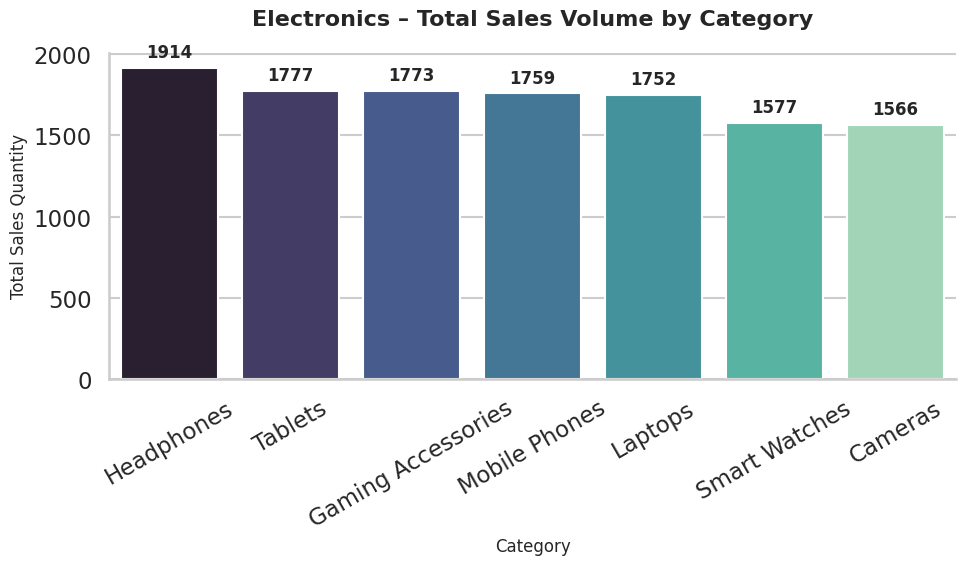

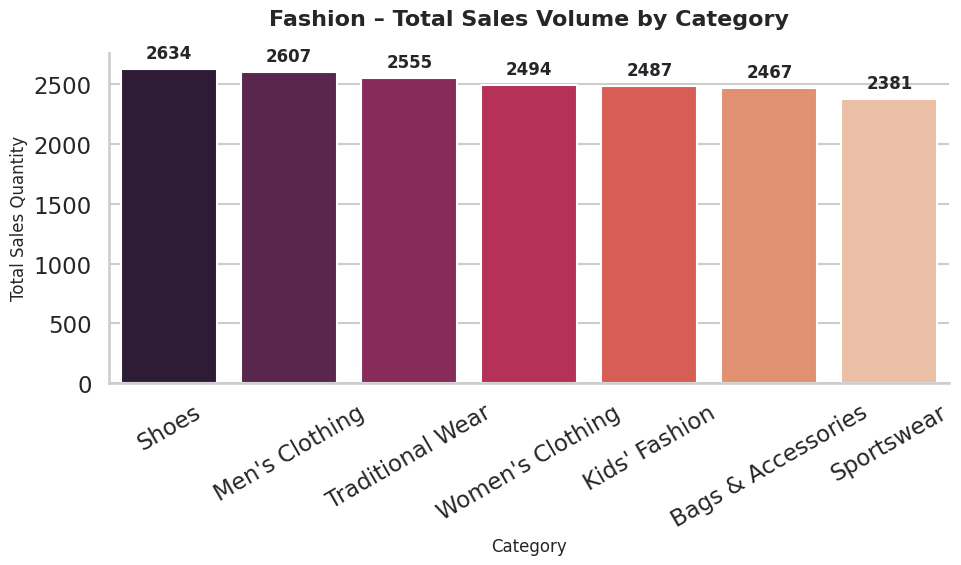

In [ ]:
# 1) Product category with the most sales volume
elec_cat_sales = (
    electronics_clean.groupby("category", as_index=False)["quantity"]
    .sum()
    .sort_values("quantity", ascending=False)
)

fash_cat_sales = (
    fashion_clean.groupby("category", as_index=False)["quantity"]
    .sum()
    .sort_values("quantity", ascending=False)
)

barplot_with_labels(
    elec_cat_sales,
    x="category",
    y="quantity",
    title="Electronics – Total Sales Volume by Category",
    xlabel="Category",
    ylabel="Total Sales Quantity",
    rotation=30,
    palette="mako",
)

barplot_with_labels(
    fash_cat_sales,
    x="category",
    y="quantity",
    title="Fashion – Total Sales Volume by Category",
    xlabel="Category",
    ylabel="Total Sales Quantity",
    rotation=30,
    palette="rocket",
)


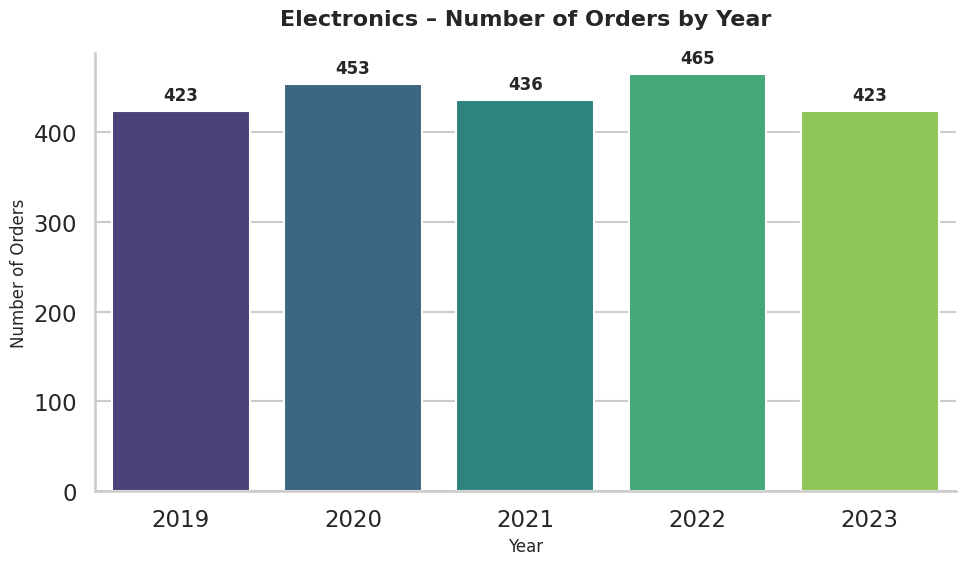

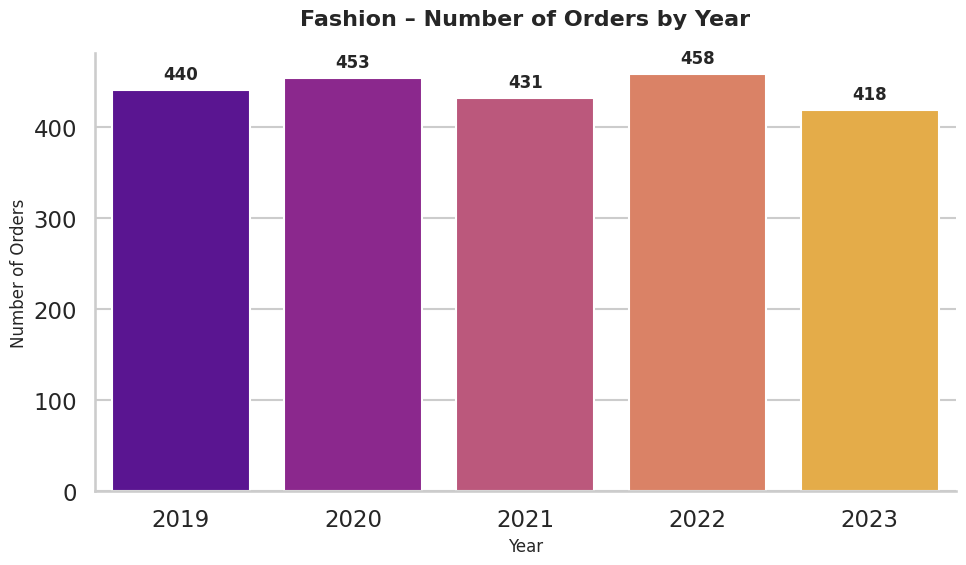

In [ ]:
# 2) Year with the most number of orders
elec_year_orders = (
    electronics_clean.dropna(subset=["year"])
    .groupby("year", as_index=False)["transaction_id"]
    .count()
    .rename(columns={"transaction_id": "order_count"})
    .sort_values("year")
)
elec_year_orders["year"] = elec_year_orders["year"].astype(int)
elec_year_orders["order_count"] = elec_year_orders["order_count"].astype(int)

fash_year_orders = (
    fashion_clean.dropna(subset=["year"])
    .groupby("year", as_index=False)["transaction_id"]
    .count()
    .rename(columns={"transaction_id": "order_count"})
    .sort_values("year")
)
fash_year_orders["year"] = fash_year_orders["year"].astype(int)
fash_year_orders["order_count"] = fash_year_orders["order_count"].astype(int)

barplot_with_labels(
    elec_year_orders,
    x="year",
    y="order_count",
    title="Electronics – Number of Orders by Year",
    xlabel="Year",
    ylabel="Number of Orders",
    rotation=0,
    palette="viridis",
)

barplot_with_labels(
    fash_year_orders,
    x="year",
    y="order_count",
    title="Fashion – Number of Orders by Year",
    xlabel="Year",
    ylabel="Number of Orders",
    rotation=0,
    palette="plasma",
)


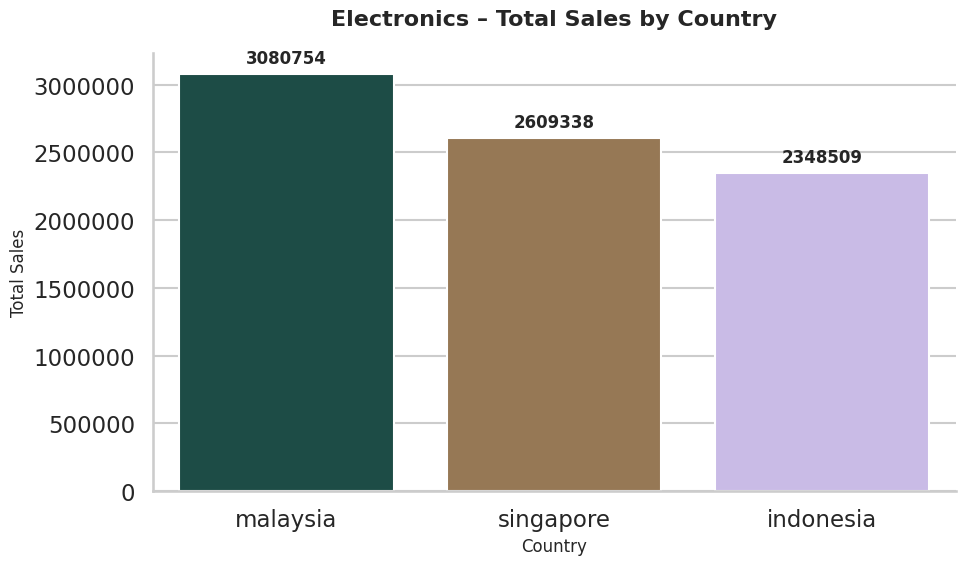

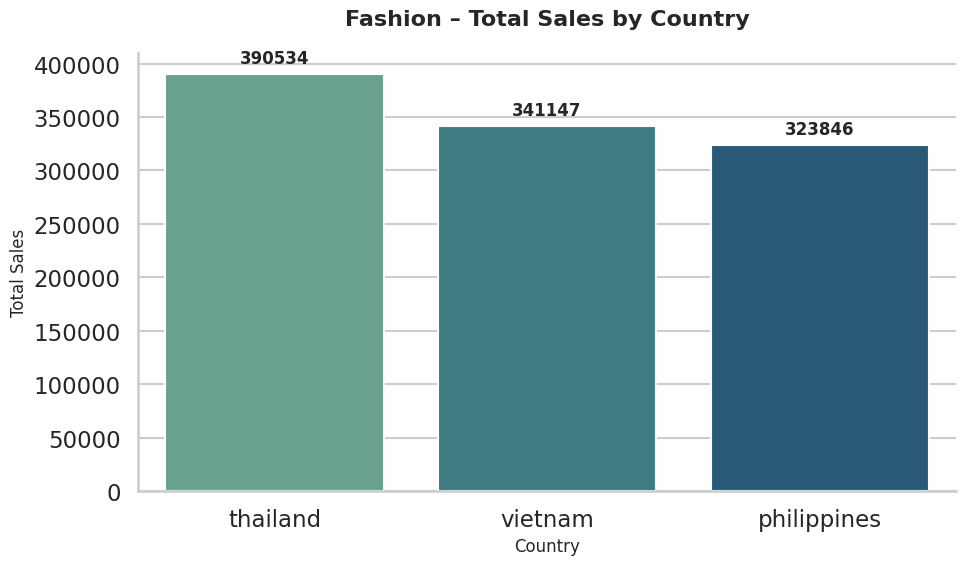

In [ ]:
# 3) Country with the highest total sales
elec_region_sales = (
    electronics_clean.groupby("region", as_index=False)["total_price"]
    .sum()
    .sort_values("total_price", ascending=False)
)

fash_region_sales = (
    fashion_clean.groupby("region", as_index=False)["total_price"]
    .sum()
    .sort_values("total_price", ascending=False)
)

barplot_with_labels(
    elec_region_sales,
    x="region",
    y="total_price",
    title="Electronics – Total Sales by Country",
    xlabel="Country",
    ylabel="Total Sales",
    rotation=0,
    palette="cubehelix",
)

barplot_with_labels(
    fash_region_sales,
    x="region",
    y="total_price",
    title="Fashion – Total Sales by Country",
    xlabel="Country",
    ylabel="Total Sales",
    rotation=0,
    palette="crest",
)

## **Task: 4**

In [ ]:
# =========================
# Task 4 – Plot Evaluation & Improvement
# =========================

# ---------------------------------------------------------
# Ensure order_date is datetime and derive year
# ---------------------------------------------------------
electronics_clean["order_date"] = pd.to_datetime(
    electronics_clean["order_date"], errors="coerce", dayfirst=True
)
fashion_clean["order_date"] = pd.to_datetime(
    fashion_clean["order_date"], errors="coerce", dayfirst=True
)

electronics_clean["year"] = electronics_clean["order_date"].dt.year.astype("Int64")
fashion_clean["year"] = fashion_clean["order_date"].dt.year.astype("Int64")


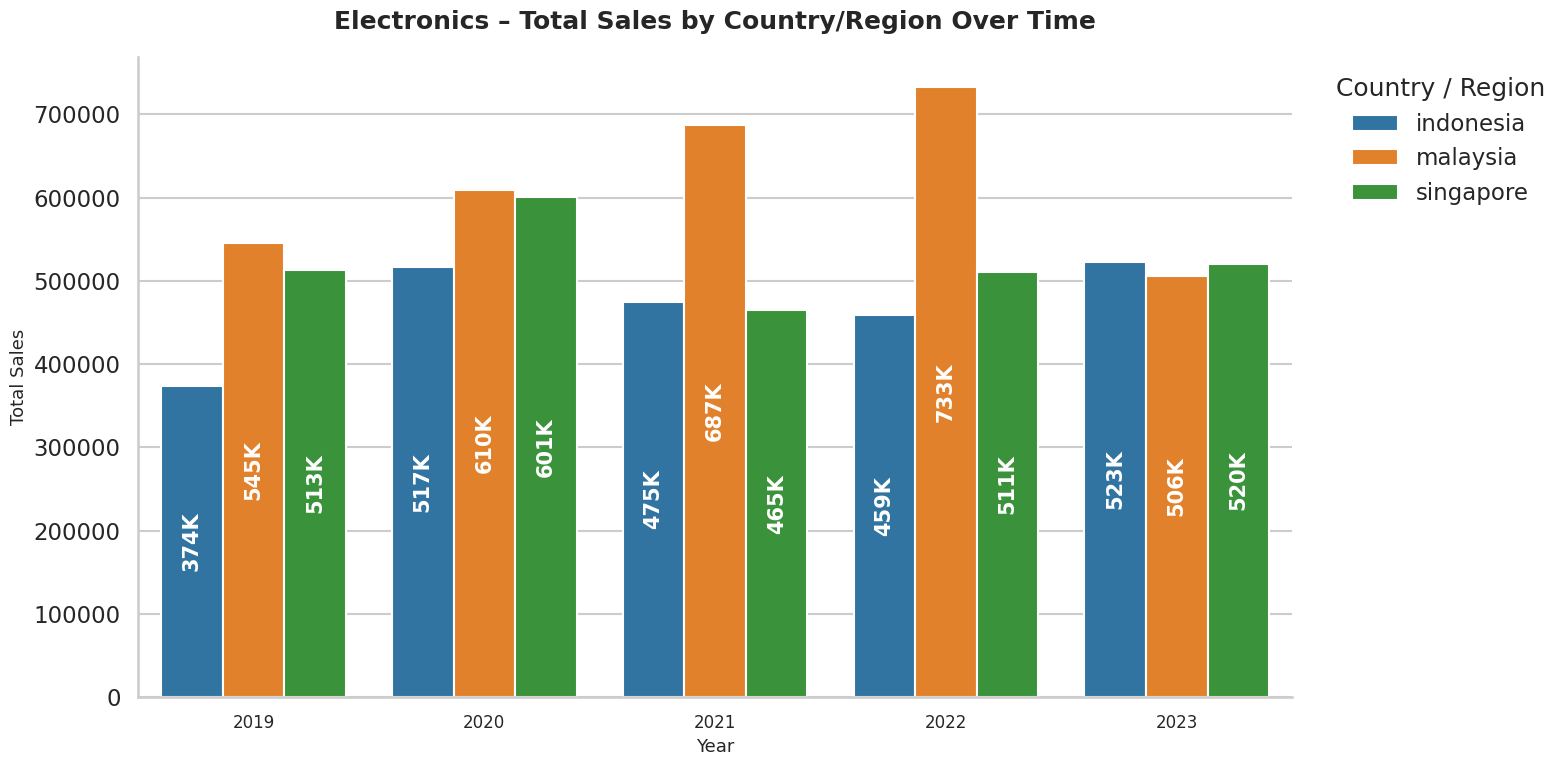

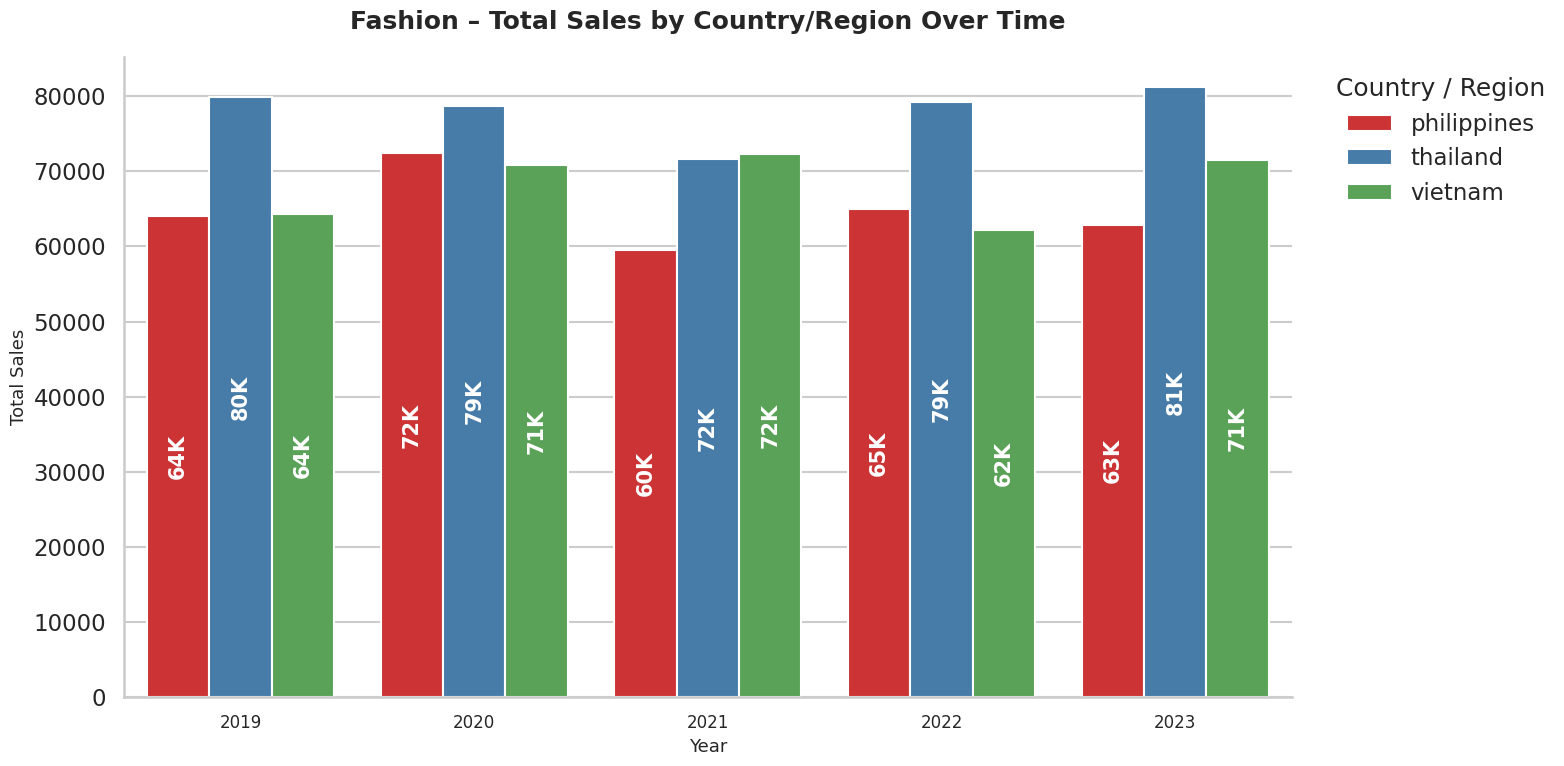

In [ ]:
# ---------------------------------------------------------
# Cell 1: Alternative plot: total sales by country over time
# ---------------------------------------------------------

def plot_sales_by_region_over_time(df, dataset_name, palette="tab10"):
    sales_time = (
        df.dropna(subset=["year"])
        .groupby(["year", "region"], as_index=False)["total_price"]
        .sum()
        .sort_values(["year", "region"])
    )

    sales_time["year"] = sales_time["year"].astype(int)

    plt.figure(figsize=(16, 8))
    ax = sns.barplot(
        data=sales_time,
        x="year",
        y="total_price",
        hue="region",
        palette=palette
    )

    ax.set_title(
        f"{dataset_name} – Total Sales by Country/Region Over Time",
        fontsize=18,
        weight="bold",
        pad=20
    )
    ax.set_xlabel("Year", fontsize=13)
    ax.set_ylabel("Total Sales", fontsize=13)
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, _: f"{val:.0f}"))

    years = sorted(sales_time["year"].unique())
    ax.set_xticks(range(len(years)))
    ax.set_xticklabels([str(y) for y in years], fontsize=12)

    # Add exact values inside each bar
    for p in ax.patches:
        height = p.get_height()
        if not np.isnan(height) and height > 0:
            ax.annotate(
                f"{height/1000:.0f}K",
                (p.get_x() + p.get_width() / 2., height * 0.5),  # place inside bar
                ha="center",
                va="center",
                fontsize=15,
                fontweight="bold",
                color="white",
                rotation=90
            )

    plt.legend(title="Country / Region", bbox_to_anchor=(1.02, 1), loc="upper left")
    sns.despine()
    plt.tight_layout()
    plt.show()

    return sales_time


elec_sales_time = plot_sales_by_region_over_time(electronics_clean, "Electronics", palette="tab10")
fash_sales_time = plot_sales_by_region_over_time(fashion_clean, "Fashion", palette="Set1")

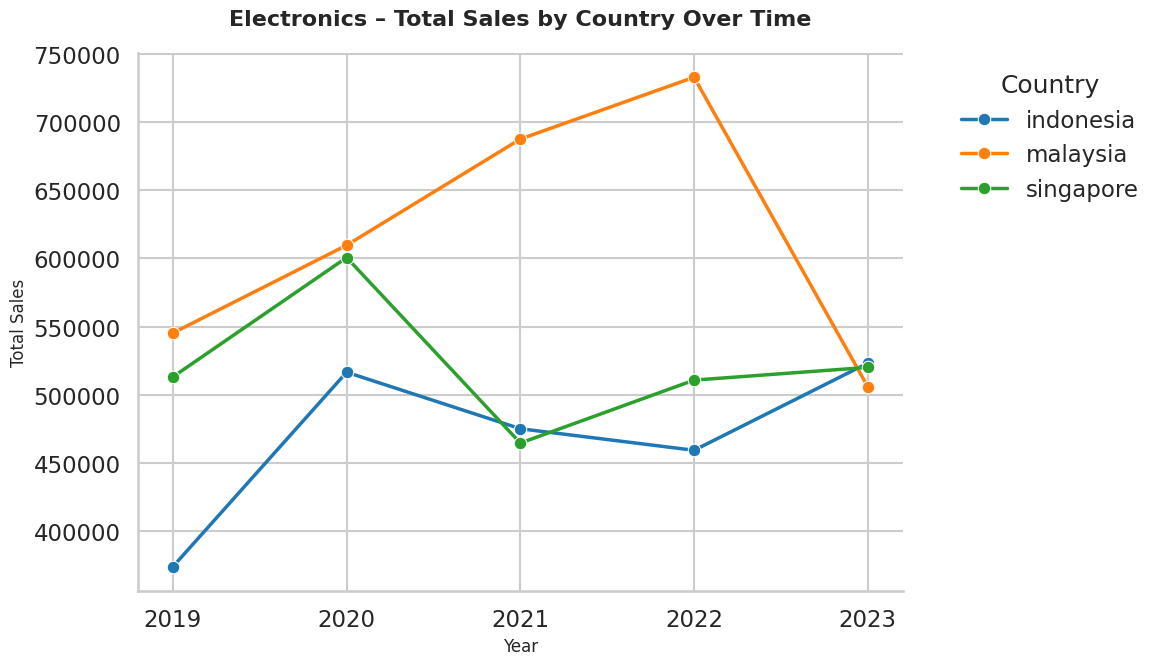

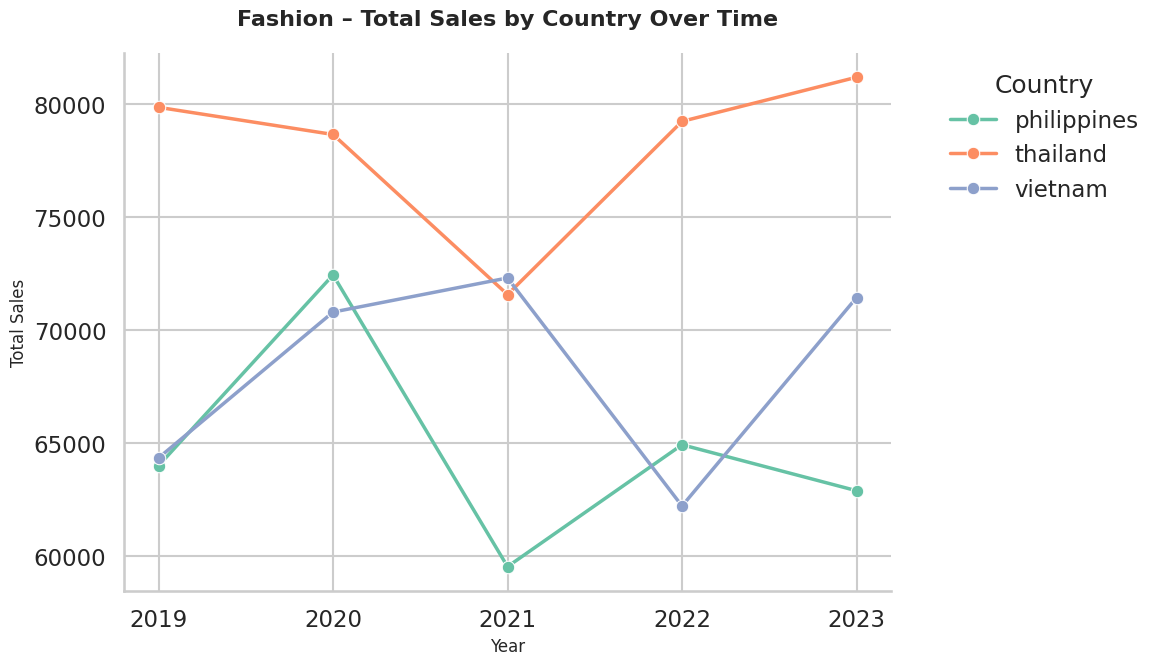

In [ ]:
# ---------------------------------------------------------
# Alternative Time Series Line Chart
# ---------------------------------------------------------

def plot_sales_by_region_over_time(df, dataset_name, palette="tab10"):
    sales_time = (
        df.dropna(subset=["year"])
        .groupby(["year", "region"], as_index=False)["total_price"]
        .sum()
        .sort_values(["year", "region"])
    )

    sales_time["year"] = sales_time["year"].astype(int)

    plt.figure(figsize=(12, 7))
    ax = sns.lineplot(
        data=sales_time,
        x="year",
        y="total_price",
        hue="region",
        marker="o",
        linewidth=2.5,
        palette=palette
    )

    years = sorted(sales_time["year"].unique())
    ax.set_xticks(years)
    ax.set_xticklabels([str(y) for y in years])

    ax.set_title(f"{dataset_name} – Total Sales by Country Over Time", fontsize=16, weight="bold", pad=20)
    ax.set_xlabel("Year", fontsize=12)
    ax.set_ylabel("Total Sales", fontsize=12)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, _: f"{val:.0f}"))

    plt.legend(title="Country", bbox_to_anchor=(1.05, 1), loc="upper left")
    sns.despine()
    plt.tight_layout()
    plt.show()

    return sales_time


elec_sales_time = plot_sales_by_region_over_time(electronics_clean, "Electronics", palette="tab10")
fash_sales_time = plot_sales_by_region_over_time(fashion_clean, "Fashion", palette="Set2")

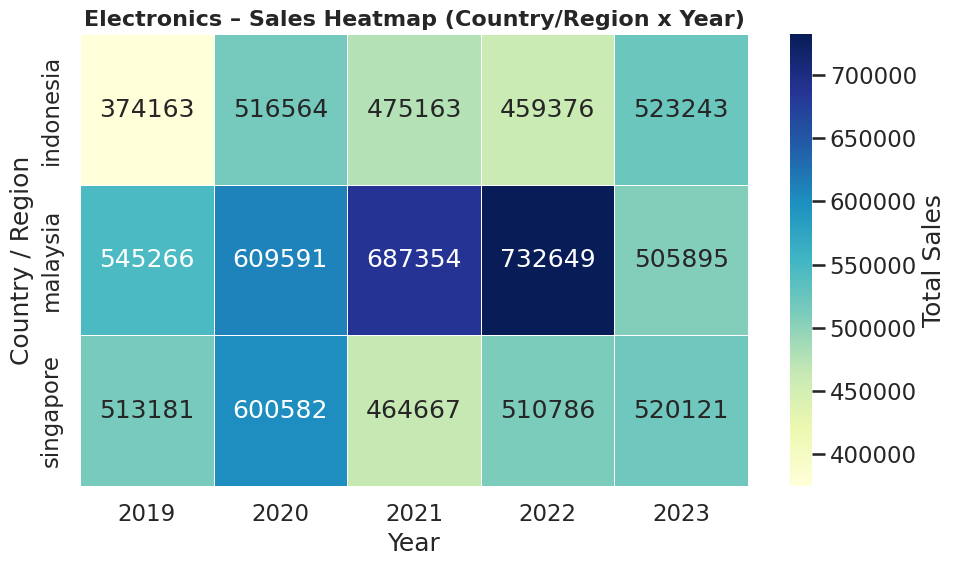

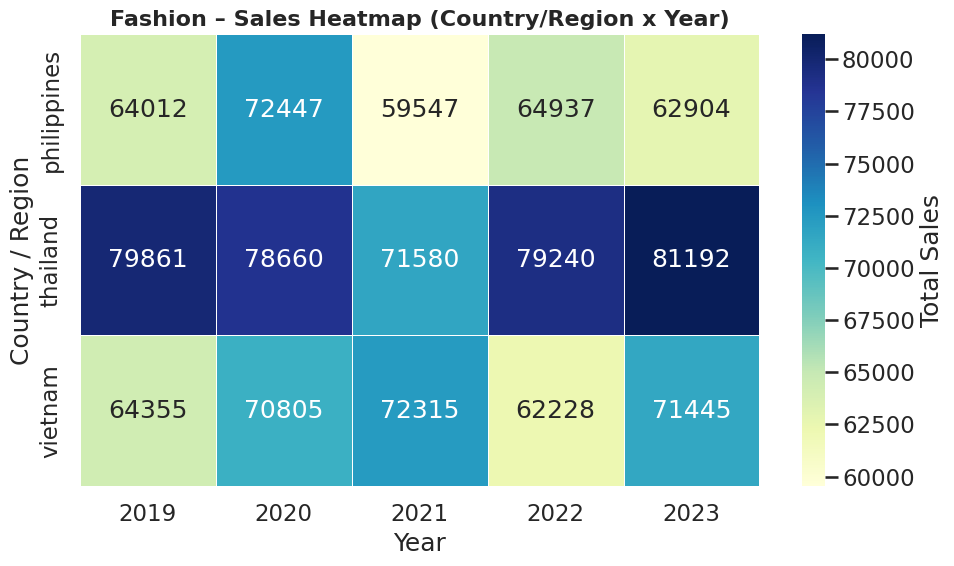

In [ ]:
# ---------------------------------------------------------
# Alternative plot: heatmap of country x year sales
# ---------------------------------------------------------

def country_year_sales(df, dataset_name):
    tmp = (
        df.dropna(subset=["order_date"])
        .copy()
    )

    tmp["year"] = pd.to_datetime(tmp["order_date"], errors="coerce", dayfirst=True).dt.year
    tmp = tmp.dropna(subset=["year"])
    tmp["year"] = tmp["year"].astype(int)

    tmp = (
        tmp.groupby(["region", "year"], as_index=False)["total_price"]
        .sum()
        .sort_values(["region", "year"])
    )

    pivot = tmp.pivot(index="region", columns="year", values="total_price").fillna(0)

    plt.figure(figsize=(10, 6))
    sns.heatmap(
        pivot,
        annot=True,
        fmt=".0f",
        cmap="YlGnBu",
        cbar_kws={"label": "Total Sales"},
        linewidths=0.5,
        linecolor="white",
    )
    plt.title(f"{dataset_name} – Sales Heatmap (Country/Region x Year)", fontsize=16, weight="bold")
    plt.xlabel("Year")
    plt.ylabel("Country / Region")
    plt.tight_layout()
    plt.show()

    return tmp, pivot


elec_country_year, elec_pivot = country_year_sales(electronics_clean, "Electronics")
fash_country_year, fash_pivot = country_year_sales(fashion_clean, "Fashion")

## **Task: 5**

In [ ]:
# =====================================
# Task 5 – Sales Trend Analysis
# =====================================

# ---------------------------------------------------------
# Ensure date is datetime and derive year
# ---------------------------------------------------------
electronics_clean["year"] = electronics_clean["order_date"].dt.year.astype("Int64")
fashion_clean["year"] = fashion_clean["order_date"].dt.year.astype("Int64")


###Best-Selling Brands in Malaysia & Indonesia

,region,brand,quantity
0,indonesia,Xiaomi,291
1,indonesia,Samsung,288
2,indonesia,Apple,274
3,malaysia,Logitech,434
4,malaysia,Oppo,348
5,malaysia,Apple,346


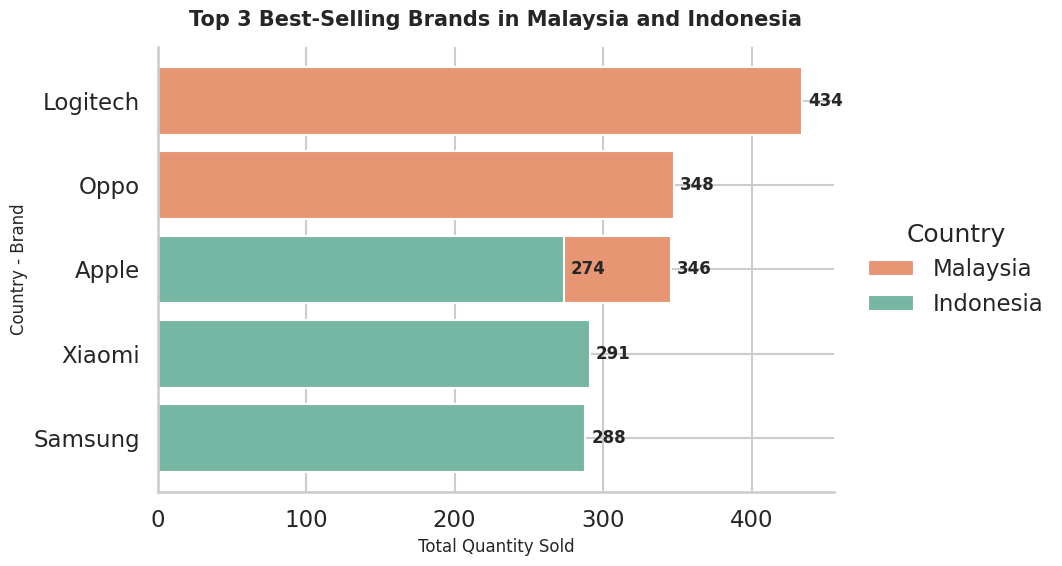

In [ ]:
# ---------------------------------------------------------
# Cell 1: Best-selling brand in Malaysia and Indonesia
#         Measure = total quantity sold
# ---------------------------------------------------------
def best_selling_brand_by_country(elec_df, countries=("malaysia", "indonesia")):
    elec_sub = elec_df[elec_df["region"].isin(countries)].copy()

    brand_qty = (
        elec_sub.groupby(["region", "brand"], as_index=False)["quantity"]
        .sum()
        .sort_values(["region", "quantity"], ascending=[True, False])
    )

    best_brands = brand_qty.groupby("region").head(3).reset_index(drop=True)

    display(Markdown("###Best-Selling Brands in Malaysia & Indonesia"))
    display(
        best_brands.style.background_gradient(cmap="YlOrRd").set_table_styles(
            [{"selector": "th", "props": [("background-color", "#7c2d12"), ("color", "white")]}]
        )
    )

    # Create a clean label and sort descending
    plot_df = best_brands.copy()
    plot_df["label"] = plot_df["brand"]
    plot_df = plot_df.sort_values("quantity", ascending=False)

    plt.figure(figsize=(11, 6))
    colors = plot_df["region"].map({
        "malaysia": "#e79673",
        "indonesia": "#76b7a4"
    })

    ax = plt.barh(plot_df["label"], plot_df["quantity"], color=colors)

    plt.title("Top 3 Best-Selling Brands in Malaysia and Indonesia",
              fontsize=15, weight="bold", pad=15)
    plt.xlabel("Total Quantity Sold", fontsize=12)
    plt.ylabel("Country - Brand", fontsize=12)
    plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda val, _: f"{val:.0f}"))

    # Put highest value at top
    plt.gca().invert_yaxis()

    # Add labels at the end of each bar
    for bar in ax:
        width = bar.get_width()
        plt.text(
            width + 4,
            bar.get_y() + bar.get_height() / 2,
            f"{width:.0f}",
            va="center",
            ha="left",
            fontsize=12,
            fontweight="bold"
        )

    # Manual legend
    from matplotlib.patches import Patch
    legend_handles = [
        Patch(facecolor="#e79673", label="Malaysia"),
        Patch(facecolor="#76b7a4", label="Indonesia")
    ]
    plt.legend(handles=legend_handles, title="Country", loc="center left",
    bbox_to_anchor=(1.02, 0.5), frameon=False)

    sns.despine()
    plt.tight_layout()
    plt.show()

    return best_brands


best_brands_MI = best_selling_brand_by_country(
    electronics_clean, countries=("malaysia", "indonesia")
)

### Sales Consistency by Country (Combined Electronics + Fashion)

,region,mean,std,count,cv
0,thailand,78106.73,3767.60,5,0.05
1,vietnam,68229.33,4601.47,5,0.07
2,philippines,64769.27,4751.65,5,0.07
3,singapore,521867.53,49165.74,5,0.09
4,indonesia,469701.81,59847.37,5,0.13
5,malaysia,616150.88,94691.37,5,0.15


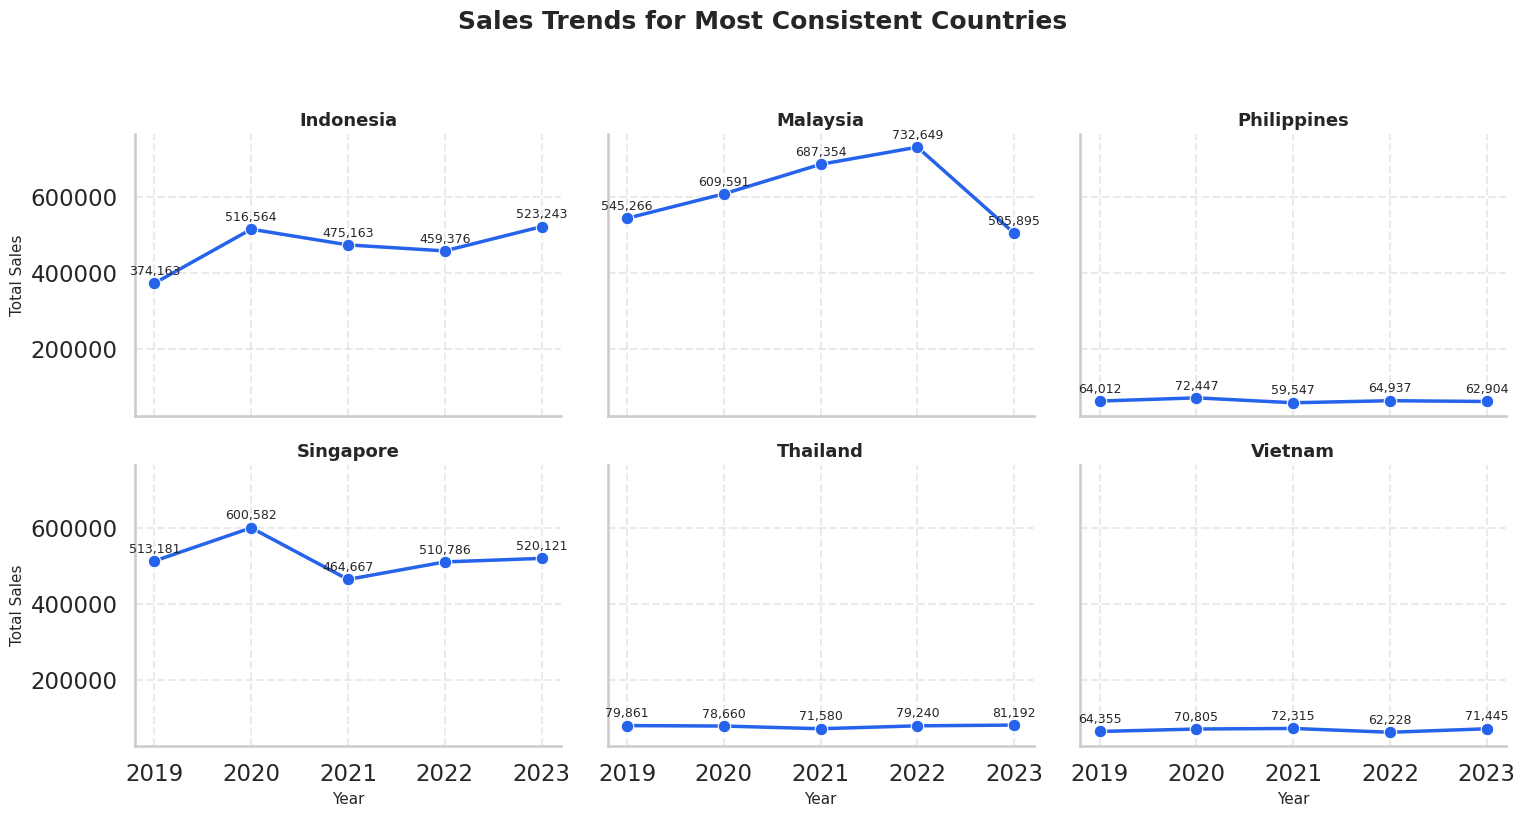

In [ ]:
# ---------------------------------------------------------
# Cell 2: Most consistent country on sales over the years
# ---------------------------------------------------------

# Most consistent country (Table)

def most_consistent_country(elec_df, fash_df):
    combined = pd.concat(
        [
            elec_df[["region", "year", "total_price"]],
            fash_df[["region", "year", "total_price"]],
        ],
        ignore_index=True,
    )

    combined = combined.dropna(subset=["year"]).copy()
    combined["year"] = combined["year"].astype(int)

    country_year_sales = (
        combined.groupby(["region", "year"], as_index=False)["total_price"]
        .sum()
        .sort_values(["region", "year"])
    )

    stats = (
        country_year_sales.groupby("region")["total_price"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    stats["cv"] = stats["std"] / stats["mean"]

    display(Markdown("### Sales Consistency by Country (Combined Electronics + Fashion)"))

    filtered = stats[stats["count"] >= 2].copy()
    most_consistent = filtered.sort_values("cv").head(6).reset_index(drop=True)

    display(
        most_consistent.style
        .format({"mean": "{:.2f}", "std": "{:.2f}", "count": "{:.0f}", "cv": "{:.2f}"})
        .background_gradient(cmap="PuBuGn", subset=["mean", "std", "count", "cv"], low=0.8, high=0.95)
    )

    return stats, most_consistent, country_year_sales

# Most consistent country (Plot)

def plot_small_multiples_sales(country_year_sales, selected_regions=None):
    df = country_year_sales.copy()

    if selected_regions is not None:
        df = df[df["region"].isin(selected_regions)].copy()

    df = df.sort_values(["region", "year"])

    sns.set_theme(style="whitegrid", context="talk")

    g = sns.FacetGrid(
        df,
        col="region",
        col_wrap=3,
        height=4,
        aspect=1.3,
        sharex=True,
        sharey=True
    )

    g.map_dataframe(
        sns.lineplot,
        x="year",
        y="total_price",
        marker="o",
        linewidth=2.5,
        color="#2563eb"
    )

    for ax, region in zip(g.axes.flat, df["region"].unique()):
        region_df = df[df["region"] == region].sort_values("year")

        for x, y in zip(region_df["year"], region_df["total_price"]):
            ax.annotate(
                f"{y:,.0f}",
                (x, y),
                textcoords="offset points",
                xytext=(0, 6),
                ha="center",
                fontsize=9
            )

        ax.set_title(region.title(), fontsize=13, weight="bold")
        ax.set_xlabel("Year", fontsize=11)
        ax.set_ylabel("Total Sales", fontsize=11)
        ax.ticklabel_format(style="plain", axis="y")
        ax.grid(True, linestyle="--", alpha=0.4)

    g.fig.suptitle(
        "Sales Trends for Most Consistent Countries",
        fontsize=18,
        weight="bold",
        y=1.03
    )

    plt.tight_layout()
    plt.show()


# Run analysis
stats, most_consistent, country_year_sales = most_consistent_country(
    electronics_clean, fashion_clean
)

plot_small_multiples_sales(
    country_year_sales,
    selected_regions=most_consistent["region"].tolist()
)

### Correlation Matrix – Electronics

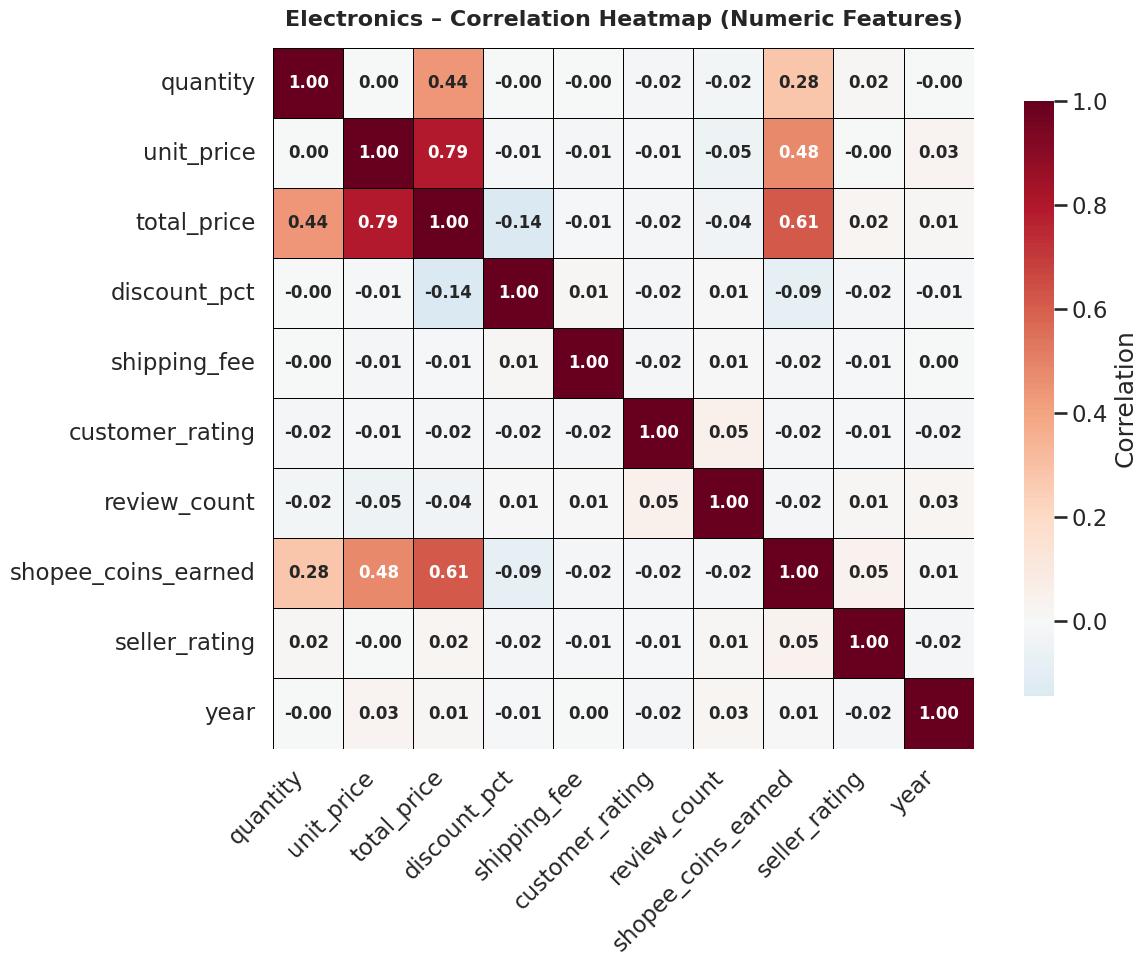

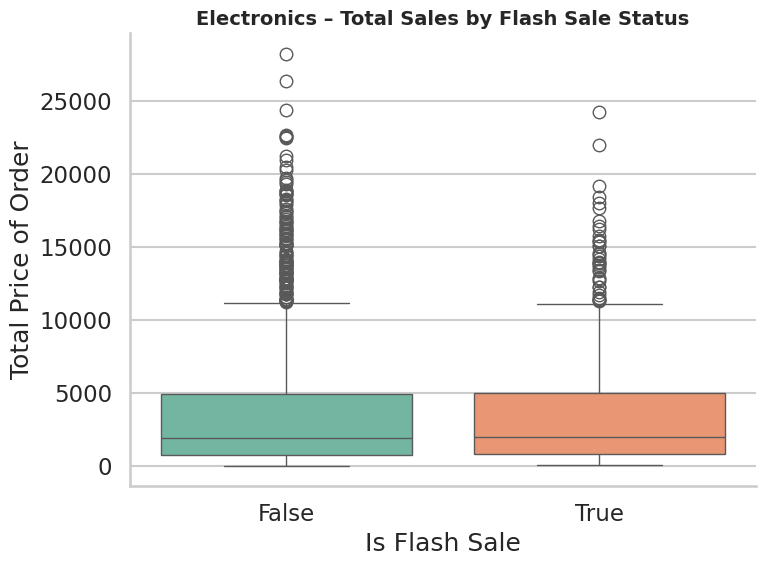

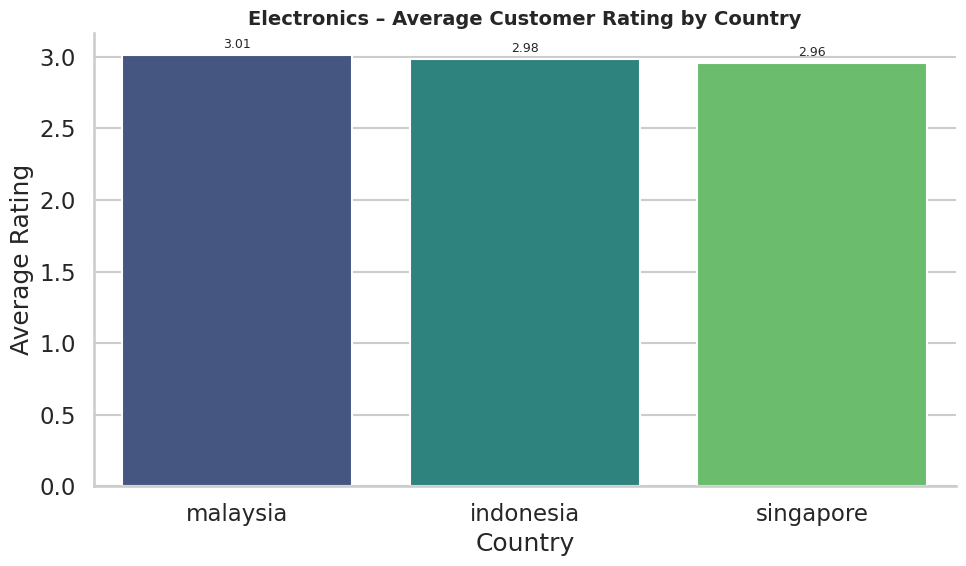

### Correlation Matrix – Fashion

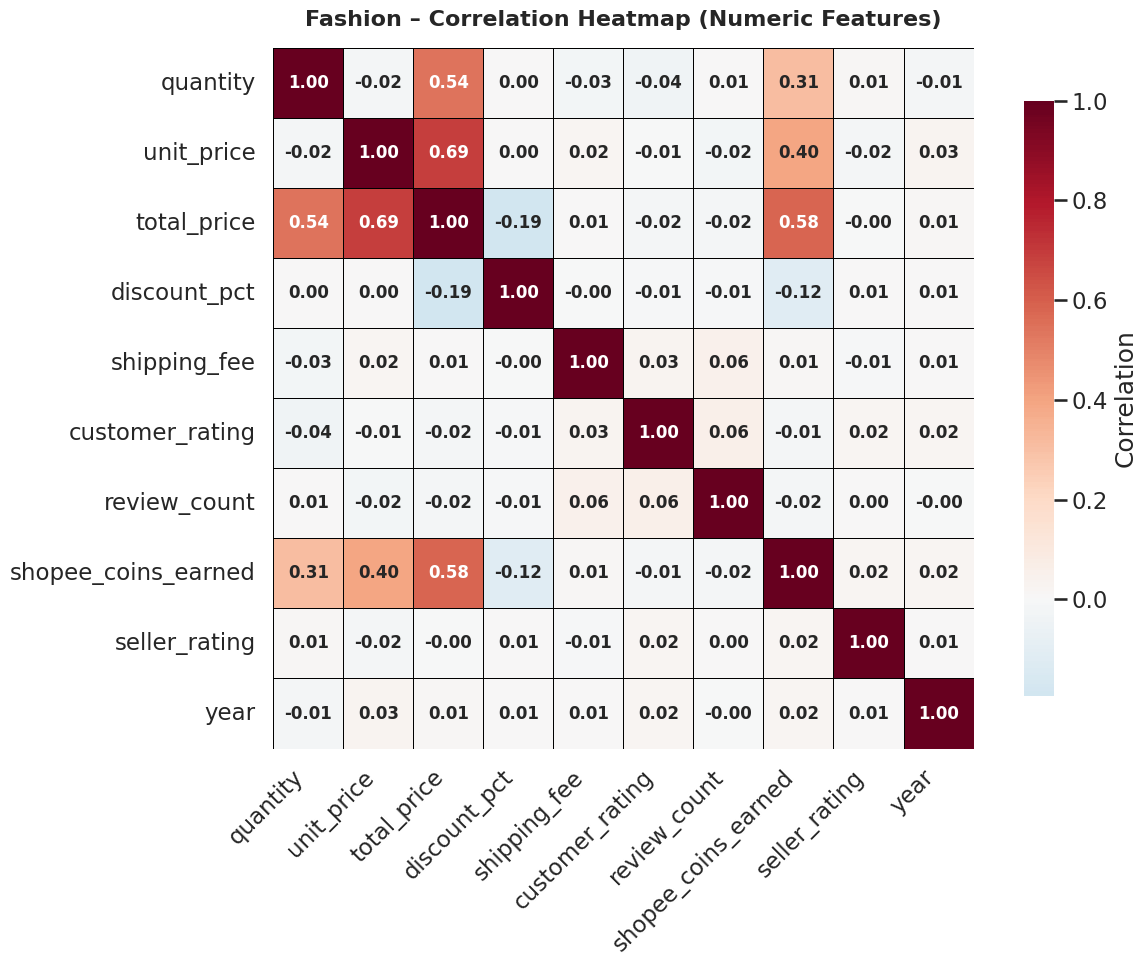

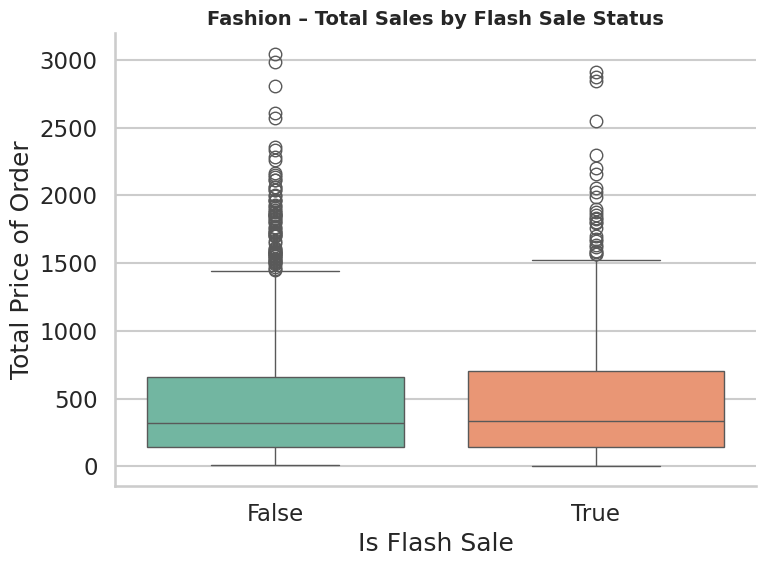

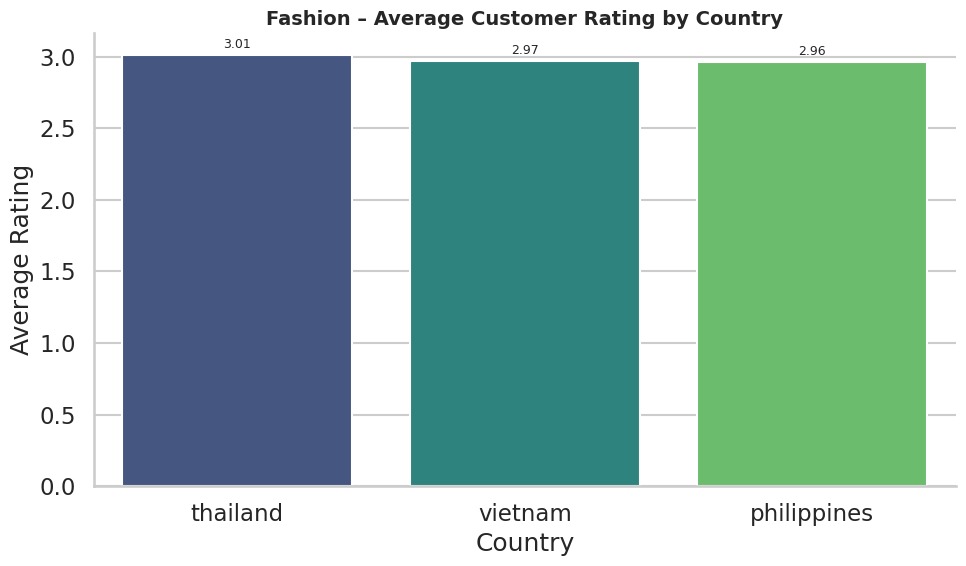

In [ ]:
# ---------------------------------------------------------
# Cell 3: Correlation among features
# ---------------------------------------------------------
def correlation_analysis(df, dataset_name):
    display(Markdown(f"### Correlation Matrix – {dataset_name}"))

    num_cols = df.select_dtypes(include="number").columns
    corr = df[num_cols].corr()

# Heatmap

    plt.figure(figsize=(13, 10))
    ax = sns.heatmap(
    corr,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 12, "weight": "bold"},
    square=True,
    linewidths=0.6,
    linecolor="black",
    cbar_kws={"shrink": 0.85, "label": "Correlation"},
)

    plt.title(f"{dataset_name} – Correlation Heatmap (Numeric Features)",
          fontsize=16, weight="bold", pad=16)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

# Boxplot

    if "is_flash_sale" in df.columns:
        plt.figure(figsize=(8, 6))
        sns.boxplot(
            data=df,
            x="is_flash_sale",
            y="total_price",
            palette="Set2",
        )
        plt.title(f"{dataset_name} – Total Sales by Flash Sale Status", fontsize=14, weight="bold")
        plt.xlabel("Is Flash Sale")
        plt.ylabel("Total Price of Order")
        sns.despine()
        plt.tight_layout()
        plt.show()

# Barplot

    if "customer_rating" in df.columns and "region" in df.columns:
        rating_by_region = (
            df.groupby("region", as_index=False)["customer_rating"]
            .mean()
            .dropna()
            .sort_values("customer_rating", ascending=False)
        )

        plt.figure(figsize=(10, 6))
        ax = sns.barplot(
            data=rating_by_region,
            x="region",
            y="customer_rating",
            palette="viridis",
        )
        ax.set_title(f"{dataset_name} – Average Customer Rating by Country", fontsize=14, weight="bold")
        ax.set_xlabel("Country")
        ax.set_ylabel("Average Rating")
        annotate_bars(ax, fmt="{:.2f}")
        sns.despine()
        plt.tight_layout()
        plt.show()

    return corr


elec_corr = correlation_analysis(electronics_clean, "Electronics")
fash_corr = correlation_analysis(fashion_clean, "Fashion")